# Elektronentemperatur von H-II-Regionen

Das Notebook misst in SDSS-Spektren der Spiralgalaxie M 101 die schwachen „auroralen“ Linien [O III] 4363, [N II] 5755, [S III] 6312 und [O II] 7320/7330, bestimmt daraus mit einem selbst gelösten Fünf-Niveau-Atom (Atomdaten aus der PyNeb-Datenbank) die Elektronentemperatur des Gases und mit ihr die Sauerstoffhäufigkeit ohne empirische Eichung, die sogenannte direkte Methode. Temperaturen, Häufigkeiten und der Metallizitätsgradient werden Faser für Faser mit dem Projekt CHAOS (Croxall et al. 2016) verglichen, und die direkte Methode wird gegen fünf Eichungen aus starken Linien gestellt.

Wie misst man die Temperatur eines Gases, das 24 Millionen Lichtjahre entfernt ist, und warum muss man sie kennen, um seinen Sauerstoff zu zählen?

#### **Hintergrund**

H-II-Regionen sind Gaswolken, die junge, heiße Sterne ionisieren und zum Leuchten bringen. Aus ihren hellen Emissionslinien liest man ab, wie viel Sauerstoff das Gas enthält, also wie weit die chemische Anreicherung durch frühere Sterngenerationen fortgeschritten ist. Im Notebook [Emissionslinien von H-II-Regionen](https://github.com/deltorobarba/science/blob/main/astro/galaxies_hiiregions.ipynb) blieb dabei eine unbequeme Frage offen: Dieselben Spektren von M 101 ergaben je nach Eichung Häufigkeiten, die um 0.6 dex (Faktor 4) auseinanderlagen. Der Grund ist die Temperatur. Wie hell eine Linie pro Sauerstoffion leuchtet, hängt exponentiell davon ab, wie heiß das Gas ist; wer die Temperatur nicht kennt, muss sie über eine Eichung erraten.

Man kann die Temperatur aber messen. Dasselbe Ion strahlt aus zwei verschieden hoch liegenden Energieniveaus; das Verhältnis der beiden Linien wirkt wie ein Thermometer. Der Haken: Die Linie aus dem oberen Niveau ist 100- bis 500-mal schwächer als die starken Linien. Forschende messen solche „auroralen“ Linien deshalb mit 8-m-Teleskopen und langen Belichtungen, etwa im Projekt CHAOS (Chemical Abundances of Spirals) am Large Binocular Telescope. Die so gewonnenen direkten Häufigkeiten sind der Anker für Metallizitätsgradienten, für die Masse-Metallizitäts-Beziehung von Galaxien und für jede Eichung aus starken Linien.

Dieses Notebook versucht dasselbe mit den Spektren, die der Sloan Digital Sky Survey (SDSS) zufällig auf die H-II-Regionen von M 101 gelegt hat, löst die Atomphysik selbst und prüft jeden Schritt an CHAOS, das dieselbe Galaxie vermessen hat.

<a id="landkarte"></a>Landkarte:

- **Daten**
  - [Die H-II-Regionen von M 101 (Schritt 1)](#exp-1): 54 SDSS-Fasern auf Gas, 102 CHAOS-Regionen, 14 Paare innerhalb von 3″.
  - [Erster Blick auf die schwachen Linien (Schritt 2)](#exp-2): In NGC 5471 ist [O III] 4363 ein Viertel so hoch wie Hγ, [O III] 5007 und Hα sind gesättigt.
- **Reduktion**
  - [Linienfits mit fester Lage und Breite (Schritt 3)](#exp-3): [O III] 4363 in 15 Fasern mit S/N > 5; das Rauschen allein erzeugt nie S/N > 5.
  - [Gesättigte Linien und Staub (Schritt 4)](#exp-4): 5007 = 2.98 × 4959 ersetzt gesättigte Linien, der Staub hat im Median E(B−V) = 0.21 mag.
  - [Die Dichte (Schritt 5)](#exp-5): etwa 60 Elektronen pro cm³; für die Thermometer spielt die Dichte bis 1000 cm⁻³ kaum eine Rolle.
- **Eigene Messung**
  - [Das Atom als Thermometer (Schritt 6)](#exp-6): Das eigene Fünf-Niveau-Atom trifft die CHAOS-Temperaturen auf 20 bis 100 K.
  - [Die Temperaturen der Regionen (Schritt 7)](#exp-7): T[O III] steigt von 8400 K innen auf 13 100 K außen.
  - [Temperatur gegen Temperatur (Schritt 8)](#exp-8): Die drei Thermometer folgen den CHAOS-Beziehungen innerhalb der Streuung.
  - [Stapeln (Schritt 9)](#exp-9): Neun innere Fasern ohne Einzelnachweis ergeben zusammen [O III] 4363 mit S/N 8 und etwa 8000 K.
- **Modell und Fit**
  - [Von der Temperatur zur Häufigkeit (Schritt 10)](#exp-10): 500 K mehr senken O/H um 0.06 bis 0.19 dex; direkte Häufigkeiten in 19 Fasern.
  - [Der direkte Metallizitätsgradient (Schritt 11)](#exp-11): 12 + log(O/H) = 8.72 − 0.74·R/R25.
- **Eigene Messung gegen den Katalog**
  - [Faser für Faser gegen CHAOS (Schritt 12)](#exp-12): Linien, Temperaturen und O/H stimmen im Median, die Streuung kommt von den verschiedenen Blenden.
  - [Der Gradient gegen CHAOS (Schritt 13)](#exp-13): gleicher Achsenabschnitt, Steigung 0.6 σ flacher.
  - [Starke Linien gegen die direkte Methode (Schritt 14)](#exp-14): Pettini & Pagel liegen 0.12 dex zu tief, MPA-JHU 0.44 dex zu hoch.

Verwandte Notebooks: dieselben Fasern mit starken Linien, BPT-Diagramm, Dichte und Staub in [Emissionslinien von H-II-Regionen](https://github.com/deltorobarba/science/blob/main/astro/galaxies_hiiregions.ipynb); Bilder und Profile einer Spiralgalaxie in [Photometrie einer Galaxie](https://github.com/deltorobarba/science/blob/main/astro/galaxies_photometry.ipynb); Rötung aus dem Balmer-Dekrement, Rekombination im Fall B und die Sterne, die Planetarische Nebel ionisieren, in [Planetarische Nebel](https://github.com/deltorobarba/science/blob/main/astro/nebulae_planetary.ipynb).

#### **Theorie**

##### *1. H-II-Regionen als Thermostat*

Ein O-Stern mit 40 000 K Oberflächentemperatur strahlt ultraviolette Photonen ab. Jedes Photon, das ein Wasserstoffatom ionisiert, gibt dem freigesetzten Elektron die überschüssige Energie mit, im Mittel einige Elektronvolt. Das ist die **Heizung** des Gases.

**Gekühlt** wird es durch Stöße. Ein schnelles Elektron trifft ein O²⁺-Ion und hebt es in ein Niveau 2.5 eV über dem Grundzustand. Das Ion fällt zurück und sendet ein Photon bei 5007 Å aus, das den dünnen Nebel ungehindert verlässt. Die Energie ist damit aus dem Gas verschwunden. Jedes Atom mit tief liegenden Niveaus (O⁺, O²⁺, N⁺, S⁺, S²⁺) wirkt so als Kühlrippe.

Heizung und Kühlung gleichen sich bei etwa 10 000 K aus; dort haben die Elektronen im Mittel $kT \approx 0.86$ eV. Mehr Sauerstoff, Stickstoff und Schwefel bedeuten mehr Kühlrippen: Metallreiches Gas pendelt sich bei 6000 bis 8000 K ein, metallarmes bei 12 000 bis 20 000 K. In einer Spiralgalaxie, deren Häufigkeit nach außen fällt, steigt die Temperatur deshalb nach außen.

Die Temperatur ist zugleich die größte Unsicherheit bei Häufigkeiten: Wie hell eine stoßangeregte Linie pro Ion ist, hängt exponentiell an $T$ (Abschnitt 6). Darum lohnt es sich, sie zu messen.

##### *2. Verbotene Linien und das Fünf-Niveau-Atom*

O²⁺ hat zwei Elektronen in der äußeren 2p-Schale (Konfiguration 2p²). Daraus entstehen fünf tiefe Niveaus: der Grundterm ³P mit drei fast gleich hohen Unterniveaus ($J = 0, 1, 2$), darüber ¹D₂ bei 2.51 eV und ¹S₀ bei 5.35 eV. N⁺ und S²⁺ haben denselben Aufbau, O⁺ und S⁺ (2p³ bzw. 3p³) einen ähnlichen mit ⁴S, ²D und ²P.

Übergänge zwischen diesen Niveaus sind **verboten**: Sie ändern die Parität nicht, die starke elektrische Dipolstrahlung ist ausgeschlossen, nur viel schwächere Prozesse bleiben. ¹D₂ lebt deshalb etwa 37 s ($A = 0.027$ s⁻¹) statt $10^{-8}$ s wie bei erlaubten Übergängen. Im Labor würde ein Stoß das Ion vorher abregen. Im Nebel mit 100 Elektronen pro cm³ trifft das Ion aber nur etwa alle drei Tage ein Elektron, das es abregen könnte (Rate $3.8\cdot10^{-6}$ s⁻¹); es strahlt fast immer. Deshalb sieht man diese Linien nur in sehr dünnem Gas, und man schreibt sie in eckigen Klammern: [O III] 5007.

Wie stark jedes Niveau besetzt ist, folgt aus dem **statistischen Gleichgewicht**: Für jedes Niveau $i$ ist der Zufluss gleich dem Abfluss,

$$\sum_{j\neq i} N_j\,\big(n_e q_{ji} + A_{ji}\big) = N_i \sum_{j\neq i}\big(n_e q_{ij} + A_{ij}\big),$$

wobei $A_{ji}$ nur für $j > i$ (spontaner Zerfall nach unten) von null verschieden ist. Die Stoßraten kommen aus der Quantenmechanik der Elektron-Ion-Stöße:

$$q_{u\to l} = \frac{8.629\cdot10^{-6}}{g_u\sqrt{T}}\,\Upsilon_{lu}(T)\ \text{cm}^3\,\text{s}^{-1}, \qquad q_{l\to u} = \frac{g_u}{g_l}\,q_{u\to l}\,e^{-\Delta E/kT}.$$

Mit fünf Niveaus sind das fünf lineare Gleichungen; eine wird durch die Normierung $\sum N_i = 1$ ersetzt. Die Emissivität einer Linie ist $4\pi j = N_u A_{ul}\, h\nu$, pro Ion und pro Elektron gerechnet (Code: Klasse `Atom`).

**Fachbegriffe:**
- **A-Wert** $A_{ul}$: Wahrscheinlichkeit pro Sekunde, dass das Niveau $u$ spontan nach $l$ zerfällt.
- **Stoßstärke** $\Upsilon$: dimensionslose Größe aus quantenmechanischen Rechnungen, die angibt, wie wirksam Elektronenstöße einen Übergang treiben; sie hängt nur schwach von $T$ ab.
- **Statistisches Gewicht** $g = 2J + 1$: die Zahl der Zustände eines Niveaus.
- **Kritische Dichte** $n_\text{krit} = \sum A / \sum q$: Darunter führt fast jede Anregung zu einem Photon, darüber regen Stöße das Niveau meist strahlungslos ab. Für ¹D₂ von O²⁺ sind es $7\cdot10^5$ cm⁻³, für ²D von S⁺ und O⁺ nur etwa $10^3$ cm⁻³.
- **PyNeb:** eine Python-Bibliothek und Datenbank für Emissionslinien (Luridiana et al. 2015). Hier werden nur ihre Dateien mit Energien, A-Werten und Stoßstärken gelesen; die Gleichungen löst eigener Code.

##### *3. Das Linienverhältnis als Thermometer*

Ein Bild dazu: Die Niveaus ¹D und ¹S von O²⁺ sind zwei Stufen einer Treppe, 2.51 eV und 5.35 eV hoch. Die Elektronen haben bei 10 000 K im Mittel 0.86 eV; nur der schnelle Rand ihrer Maxwell-Verteilung kommt bis zur oberen Stufe. Wird das Gas kälter, schrumpft dieser Rand exponentiell. Für die Lücke von 2.84 eV zwischen den beiden Stufen ist der Boltzmann-Faktor $e^{-\Delta E/kT}$ bei 10 000 K gleich 0.037, bei 8000 K nur noch 0.016. Die Linie aus ¹S ([O III] 4363) wird also im Vergleich zu den Linien aus ¹D ([O III] 4959 und 5007) gut doppelt so schwach.

Im dünnen Gas führt jede Anregung zu einem Photon; die Anregungsrate eines Niveaus ist proportional zu $\Upsilon\,e^{-E/kT}/\sqrt{T}$. Bezieht man noch ein, welcher Anteil der Zerfälle von ¹S über 4363 läuft, folgt die klassische Formel (Osterbrock & Ferland 2006, Gl. 5.4):

$$\frac{j_{4959} + j_{5007}}{j_{4363}} \approx \frac{7.90\; e^{32\,900\,\text{K}/T}}{1 + 4.5\cdot10^{-4}\, n_e/\sqrt{T}}.$$

Bei 10 000 K und 100 cm⁻³ ergibt das 212, das Fünf-Niveau-Atom mit neueren Atomdaten 204 (Schritt 6). Misst man das Verhältnis, kennt man $T$.

Drei solche Thermometer liegen im SDSS-Spektrum:
- **[O III]** 4363 / (4959 + 5007), Energielücke $\Delta E/k \approx 33\,000$ K, misst das Gas mit O²⁺.
- **[N II]** 5755 / (6548 + 6584), $\Delta E/k \approx 25\,000$ K, misst das Gas mit N⁺ und O⁺.
- **[S III]** 6312 / (9069 + 9532), $\Delta E/k \approx 22\,800$ K, misst das Gas mit S²⁺.

Je kleiner die Lücke, desto heller bleibt die aurorale Linie in kühlem Gas. Deshalb reichen [N II] und [S III] weiter in die metallreichen inneren Regionen, wo [O III] 4363 verschwindet.

**Fachbegriffe:**
- **Aurorale Linie:** Zerfall aus dem oberen Niveau ¹S nach ¹D, benannt nach der grünen Polarlichtlinie [O I] 5577, die genauso entsteht.
- **Nebulare Linie:** Zerfall aus ¹D in den Grundterm ³P, etwa [O III] 5007; die hellsten Linien von Nebeln.
- **Elektronentemperatur** $T_e$: die Temperatur der Maxwell-Verteilung der freien Elektronen; sie bestimmt die Stoßanregung.

##### *4. Dichte und Staub*

Die Thermometer hängen kaum von der Dichte ab, solange sie weit unter der kritischen Dichte liegt (Schritt 5). Gemessen wird sie trotzdem, mit dem [S II]-Dublett 6717/6731: Die beiden oberen Niveaus liegen fast gleich hoch, haben aber verschiedene kritische Dichten. Im dünnen Gas ist das Verhältnis 1.45, im dichten etwa 0.5. Warum das so ist, steht in [Emissionslinien von H-II-Regionen](https://github.com/deltorobarba/science/blob/main/astro/galaxies_hiiregions.ipynb), Theorie, Abschnitt 4; hier rechnet das eigene Atom die Kurve.

**Staub** schwächt blaues Licht stärker als rotes. Die Thermometer verbinden Linien, die weit auseinander liegen (4363 und 5007, 6312 und 9069); ohne Korrektur wären die Verhältnisse verfälscht. Die Schwächung beschreibt das Gesetz von Cardelli, Clayton & Mathis (1989) als $k(\lambda) = A_\lambda/E(B-V)$. Die Balmer-Linien des Wasserstoffs haben feste Verhältnisse (Fall B bei 10 000 K: Hα/Hβ = 2.86, Hγ/Hβ = 0.468), daraus folgt die Rötung $E(B-V)$, und jede Linie wird entrötet:

$$\frac{I(\lambda)}{I(\text{H}\beta)} = \frac{F(\lambda)}{F(\text{H}\beta)}\;10^{\,0.4\,E(B-V)\,[k(\lambda) - k(\text{H}\beta)]}.$$

**Fachbegriffe:**
- **Fall B:** Annahme, dass der Nebel für Lyman-Photonen undurchsichtig ist; jedes wird sofort wieder absorbiert. Die Verhältnisse der Balmer-Linien liegen dann fest (Storey & Hummer 1995).
- **Rötung** $E(B-V)$: wie viel stärker der Staub blaues (B) als visuelles (V) Licht schwächt, in Magnituden.
- $F$ und $I$: gemessener Fluss und entrötete Intensität einer Linie.

##### *5. Ionisationszonen und Temperatur-Temperatur-Beziehungen*

Ein H-II-Gebiet ist wie eine Zwiebel aufgebaut. Nahe den heißen Sternen gibt es genug Photonen über 35.1 eV, um Sauerstoff zweifach zu ionisieren: Dort lebt O²⁺. Weiter außen reicht es nur für O⁺ (13.6 eV), und dort leben auch N⁺ (14.5 eV) und S⁺ (10.4 eV). S²⁺ (23.3 eV) sitzt dazwischen.

Die Zonen haben verschiedene Temperaturen, und jedes Thermometer misst seine eigene: T[O III] die O²⁺-Zone, T[N II] die O⁺-Zone, T[S III] die Zone dazwischen. Für O²⁺ braucht man deshalb T[O III], für O⁺ T[N II]. Fehlt ein Thermometer, nimmt man eine empirische **Temperatur-Temperatur-Beziehung**, hier die von CHAOS (Croxall et al. 2016, Gl. 5 bis 7, $T$ in $10^4$ K):

$$T[\text{N II}] = 0.714\,T[\text{O III}] + 0.257, \qquad T[\text{S III}] = 1.312\,T[\text{N II}] - 0.313, \qquad T[\text{S III}] = 1.265\,T[\text{O III}] - 0.232.$$

Die erste ist flacher als 1:1: In heißem, metallarmem Gas ist die O⁺-Zone kälter als die O²⁺-Zone, in kühlem, metallreichem Gas wärmer. Rangfolge im Code: für die O²⁺-Zone T[O III], sonst aus T[N II], sonst aus T[S III]; für die O⁺-Zone T[N II], sonst aus T[O III], sonst aus T[S III].

**Fachbegriffe:**
- **Ionisationsenergie:** die Energie, die ein Photon mindestens haben muss, um das nächste Elektron herauszuschlagen.
- **Zone:** der Teil des Nebels, in dem ein Ion vorherrscht.

##### *6. Von der Temperatur zur Häufigkeit*

Wasserstoff dient als Maßstab. Hβ entsteht bei der Rekombination; seine Emissivität hängt nur schwach an $T$, etwa wie $T^{-0.85}$ (Storey & Hummer 1995, $4\pi j_{\text{H}\beta}/(n_e n_p) = 1.235\cdot10^{-25}$ erg cm³ s⁻¹ bei 10 000 K). Für ein Ion $X^{i}$ mit einer stoßangeregten Linie bei $\lambda$ gilt

$$\frac{n(X^{i})}{n(\text{H}^+)} = \frac{I(\lambda)}{I(\text{H}\beta)}\;\frac{j_{\text{H}\beta}(T)}{j_\lambda(T)},$$

mit beiden Emissivitäten pro Ion und pro Elektron. Weil $j_\lambda \propto e^{-E/kT}/\sqrt{T}$ steil mit $T$ steigt, braucht man bei zu hoch geschätzter Temperatur weniger Ionen, um dieselbe Linie zu erklären: Die Häufigkeit kommt zu niedrig heraus.

In H-II-Regionen ohne He-II-Linie gibt es kaum O³⁺, also ist

$$\frac{\text{O}}{\text{H}} = \frac{\text{O}^+}{\text{H}^+} + \frac{\text{O}^{2+}}{\text{H}^+}, \qquad 12 + \log(\text{O/H}) \text{ für die Sonne} = 8.69.$$

O²⁺ kommt aus [O III] 4959 + 5007 mit der Temperatur der O²⁺-Zone. O⁺ kommt üblicherweise aus [O II] 3726 + 3729. Das ältere SDSS-Spektrum beginnt aber erst bei 3800 Å; für M 101 liegt die Linie außerhalb. Ersatz sind die auroralen [O II]-Linien 7320 und 7330 (aus ²P). Sie hängen stärker an $T$ und, weil ²D eine kritische Dichte von nur $10^3$ cm⁻³ hat, auch an der Dichte. An den CHAOS-Daten wird geprüft, dass beide Wege dasselbe O⁺ ergeben (Schritt 10).

**Fachbegriffe:**
- $12 + \log(\text{O/H})$: Zahl der Sauerstoffatome pro $10^{12}$ Wasserstoffatome, logarithmisch.
- **dex:** eine Zehnerpotenz im Logarithmus; 0.3 dex ist ein Faktor 2.
- **Direkte Methode:** Häufigkeit mit gemessener Temperatur, ohne empirische Eichung.

##### *7. Starke Linien und ihr Nullpunkt*

Wo die auroralen Linien zu schwach sind, schätzt man O/H aus den starken Linien. Es gibt zwei Familien:
- **Empirische Eichungen** wurden an Regionen mit direkter Häufigkeit angepasst: Pettini & Pagel (2004) mit $\text{N2} = \log([\text{N II}]\,6584/\text{H}\alpha)$, also $12 + \log(\text{O/H}) = 8.90 + 0.57\,\text{N2}$, und mit $\text{O3N2} = \log\frac{[\text{O III}]\,5007/\text{H}\beta}{[\text{N II}]\,6584/\text{H}\alpha}$, also $8.73 - 0.32\,\text{O3N2}$; Marino et al. (2013) mit neueren Daten: $8.743 + 0.462\,\text{N2}$ und $8.533 - 0.214\,\text{O3N2}$.
- **Theoretische Eichungen** vergleichen mehrere starke Linien mit Photoionisationsmodellen, etwa Tremonti et al. (2004) für den MPA-JHU-Katalog.

Die Familien weichen um bis zu 0.7 dex voneinander ab (Kewley & Ellison 2008); die theoretischen liegen höher. Auch die direkte Methode ist nicht ohne Zweifel: Schwankt die Temperatur innerhalb eines Nebels (Peimbert 1967), so wird 4363 vor allem in den heißen Teilen erzeugt, $T$ wird zu hoch und O/H zu niedrig gemessen. Rekombinationslinien von O²⁺, die kaum von $T$ abhängen, ergeben in extragalaktischen H-II-Regionen im Mittel 0.26 ± 0.09 dex mehr Sauerstoff (Esteban et al. 2009, darunter Regionen in M 101). Die direkte Methode ist trotzdem der gemessene, modellfreie Bezugspunkt, an dem man die anderen prüft.

##### *8. Nachweis, Rauschen und Stapeln*

Eine schwache Linie misst man am sichersten, wenn man so wenig wie möglich frei lässt. Die Lage folgt aus der Rotverschiebung der starken Linien, die Breite aus deren Breite, umgerechnet mit der Auflösung des Spektrographen (Spalte `wdisp` im SDSS-Spektrum). Frei bleiben nur die Höhe der Linie und ein lineares Kontinuum. Das Signal-Rausch-Verhältnis ist dann $\text{S/N} = F/\sigma_F$.

Bei reinem Gaußschem Rauschen hat eine Messung ohne Linie mit Wahrscheinlichkeit 0.13 % ein S/N über 3 und mit $3\cdot10^{-7}$ eines über 5. Echte Fehler sind nie ganz gaußisch; man prüft deshalb mit **Leermessungen** an Stellen ohne Linie, wie oft das Rauschen eine Linie vortäuscht.

Für die Temperatur reicht S/N 3 nicht: Weil $T$ logarithmisch vom Verhältnis abhängt, verschiebt ein Fehler von 20 % in 4363 die Temperatur bei 10 000 K um $\Delta T \approx 0.2\,T^2/(\Delta E/k) \approx 600$ K und O/H um etwa 0.1 dex.

**Stapeln:** Mittelt man $N$ gleich gute Spektren im Ruhesystem, fällt das Rauschen wie $1/\sqrt{N}$. Mit Gewichten $w_i$ zählt nur die effektive Zahl $N_\text{eff} = (\sum w_i)^2/\sum w_i^2$. Zwei Fallen: Ein Spektrum, das im Kern einer Linie fehlt (gesättigt), aber in den Flügeln mitzählt, verbiegt das Linienprofil. Und Spektren mit viel Sternlicht bringen Absorptionslinien mit, die das Kontinuum unter schwachen Linien verfälschen.

#### **Daten**

- **SDSS DR17**, abgefragt mit SQL über `astroquery.sdss`: alle Spektren in einem Kasten um M 101, deren Rotverschiebung innerhalb von 600 km/s der Galaxie liegt (etwa 76 × 200 kB). Dazu für Schritt 14 die Sauerstoffhäufigkeiten des MPA-JHU-Katalogs (Tabelle `galSpecExtra`) und ein Farbbild vom Cutout-Dienst des SkyServers.
- **CHAOS** (Croxall et al. 2016), VizieR-Katalog `J/ApJ/830/4`: Positionen und Abstände der 102 vermessenen Regionen (Tabelle 2), entrötete Linienstärken relativ zu Hβ (Tabelle 3), Temperaturen und Häufigkeiten (Tabelle 4). Der Code fragt erst CDS und dann die Spiegel an der CfA und in Japan; CDS war im November 2026 zeitweise nicht erreichbar.
- **Atomdaten** aus der Datenbank von PyNeb auf GitHub: Energieniveaus, A-Werte und Stoßstärken für O²⁺, N⁺, S²⁺, O⁺ und S⁺, dazu die Emissivitäten des Wasserstoffs im Fall B von Storey & Hummer (1995). Die Bibliothek PyNeb selbst wird nicht gebraucht.

Alle Downloads landen einmalig im Ordner `astrodata` neben dem Notebook.

**Hintergrund & Fachbegriffe:**
- **Faser:** SDSS führt das Licht jedes Ziels über eine Glasfaser zum Spektrographen, 3″ Durchmesser beim älteren SDSS-Spektrographen (3800 bis 9200 Å), 2″ bei BOSS (3600 bis 10 400 Å). Bei 7.4 Mpc sind 3″ etwa 110 pc, ein Teil einer H-II-Region.
- **Spaltspektrum:** CHAOS legt einen 1″ breiten Spalt über mehrere Regionen und zieht für jede einen Abschnitt von einigen Bogensekunden heraus; Faser und Spalt sehen also nicht genau dasselbe Gas.
- **R25:** der Radius, bei dem die Flächenhelligkeit der Galaxie im B-Band auf 25 mag pro Quadratbogensekunde fällt; für M 101 864″ = 14.4′. Abstände in Einheiten von R25 lassen sich zwischen Galaxien vergleichen.
- **Lagewinkel und Neigung:** M 101 ist um 18° gegen die Blickrichtung geneigt, die große Achse liegt bei 39° (von Norden über Osten). Damit rechnet man Positionen am Himmel in Abstände in der Scheibe um (Deprojektion), wie bei CHAOS.

In [1]:
# In Colab fehlt astroquery; lokal ist es meist schon installiert
import importlib.util, subprocess, sys
if importlib.util.find_spec("astroquery") is None:
    if "google.colab" not in sys.modules:       # lokal nichts automatisch installieren: pip würde numpy mit aktualisieren
        raise ImportError("Es fehlt astroquery; bitte lokal selbst installieren, am besten mit conda (conda-forge), "
                          "damit numpy und die übrigen Pakete unverändert bleiben")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "astroquery"], check=True)

In [2]:
import io
import os
import time
import warnings
import urllib.request
from fractions import Fraction
from pathlib import Path

# Downloads landen im Ordner "astrodata" neben dem Notebook statt in den Caches im Home-Verzeichnis.
# Das muss vor dem ersten Import von astropy passieren; sonst den Kernel neu starten.
ASTRODATA = Path.cwd() / "astrodata"
(ASTRODATA / "astropy").mkdir(parents=True, exist_ok=True)
os.environ["XDG_CACHE_HOME"] = str(ASTRODATA)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit, brentq
from astropy.io import fits
from astropy.coordinates import SkyCoord
from astropy import units as u
from astroquery.sdss import SDSS

V_SYS = 241.0                                   # systemische Geschwindigkeit von M 101 [km/s]
D_MPC = 7.4                                     # Entfernung wie bei CHAOS (Croxall et al. 2016)
R25_ARCSEC, PA_DEG, INC_DEG = 864.0, 39.0, 18.0 # Scheibenradius, Lagewinkel und Neigung wie bei CHAOS
N_E = 100.0                                     # Elektronendichte [cm⁻³] (Schritt 5)
SN_STRONG = 3.0                                 # Mindest-S/N der starken Linien
SN_AUR = 5.0                                    # Mindest-S/N der schwachen Temperaturlinien (Schritt 3)
N_MC = 500                                      # Ziehungen für die Fehlerfortpflanzung
C_KMS = 299792.458
rng = np.random.default_rng(42)
pd.set_option("display.width", 160)
np.seterr(divide="ignore", invalid="ignore")                 # log von Nicht-Nachweisen und negativen Flüssen -> NaN

VIZIER = ["https://vizier.cds.unistra.fr", "https://vizier.cfa.harvard.edu", "http://vizier.nao.ac.jp"]   # Spiegel
PYNEB = "https://raw.githubusercontent.com/Morisset/PyNeb_devel/master/pyneb/"

def download(urls, path, check=None):
    # lädt eine Datei vom ersten Server, der antwortet, und liest sie danach aus dem Cache
    path = Path(path)
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        for url in urls:
            try:
                with urllib.request.urlopen(url, timeout=30) as r:
                    data = r.read()
            except OSError:
                continue
            if check is None or check(data):
                path.write_bytes(data)
                break
        else:
            raise OSError(f"Kein Server liefert {path.name}")
    return path

def vizier_table(source):
    # eine VizieR-Tabelle als tabulatorgetrennter Text; CDS war im November 2026 zeitweise nicht erreichbar
    query = f"/viz-bin/asu-tsv?-source={source}&-out.max=unlimited&-out.all"
    p = download([m + query for m in VIZIER], ASTRODATA / "vizier" / (source.replace("/", "_") + ".tsv"),
                 check=lambda d: d.startswith(b"#"))
    lines = [l for l in p.read_text().splitlines(keepends=True) if l.strip() and not l.startswith("#")]
    df = pd.read_csv(io.StringIO("".join(lines)), sep="\t", skiprows=[1, 2], dtype=str)   # Zeilen 2, 3: Einheiten, Striche
    df.columns = [c.strip() for c in df.columns]
    return df.apply(lambda s: s.str.strip())

def sdss_query(sql, tries=3):
    # SkyServer antwortet manchmal mit 503 (überlastet); dann nach einer Pause noch einmal
    for k in range(tries):
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")      # astropy meldet, dass specObjID nicht in eine 64-Bit-Ganzzahl passt
                return SDSS.query_sql(sql, data_release=17)
        except Exception:
            if k == tries - 1:
                raise
            time.sleep(20)

In [3]:
# Atomphysik (Theorie, Abschnitte 2, 3 und 6): Fünf-Niveau-Atome, Wasserstoff-Emissivitäten, Staubgesetz
H_PLANCK, C_CGS, K_B = 6.62607e-27, 2.99792458e10, 1.380649e-16

def air2vac(lam):
    # Luft- in Vakuumwellenlänge [Å] (Morton 2000); SDSS gibt Vakuumwellenlängen an
    s2 = (1e4 / lam) ** 2
    return lam * (1 + 8.34254e-5 + 2.406147e-2 / (130 - s2) + 1.5998e-4 / (38.9 - s2))

AIR = {"OII3726": 3726.03, "OII3729": 3728.82, "Hg": 4340.47, "OIII4363": 4363.21, "Hb": 4861.33, "OIII4959": 4958.91,
       "OIII5007": 5006.84, "NII5755": 5754.59, "OI6300": 6300.30, "SIII6312": 6312.06, "NII6548": 6548.05, "Ha": 6562.80,
       "NII6584": 6583.45, "SII6717": 6716.44, "SII6731": 6730.82, "OII7320": 7320.0, "OII7330": 7330.2,
       "SIII9069": 9068.6, "SIII9532": 9530.6}
LINES = {k: air2vac(v) for k, v in AIR.items()}           # Vakuumwellenlängen [Å]

def numeric_rows(text):
    rows = []
    for line in text.splitlines():
        try:
            vals = [float(x) for x in line.split()]
        except ValueError:
            continue
        if vals:
            rows.append(vals)
    return rows

def pyneb_file(name):
    return download([PYNEB + name], ASTRODATA / "pyneb" / Path(name).name)

class Atom:
    """Fünf-Niveau-Atom im statistischen Gleichgewicht mit Atomdaten aus der PyNeb-Datenbank."""
    def __init__(self, ion, atom_src, coll_src, n=5):
        self.n = n
        self.A = np.array(numeric_rows(pyneb_file(f"atomic_data/{ion}_atom_{atom_src}.dat").read_text()))[:n, :n]
        text = pyneb_file(f"atomic_data/{ion}_coll_{coll_src}.dat").read_text()
        rows = numeric_rows(text)
        grid = np.array(rows[0][2:])
        unit = text.split("T_UNIT")[1].split()[0]                      # log(K), K/10000 oder K
        self.logT = {"log(K)": grid, "K/10000": np.log10(grid * 1e4), "K": np.log10(grid)}[unit]
        self.ups = {(int(r[0]) - 1, int(r[1]) - 1): np.array(r[2:]) for r in rows[1:]}   # Stoßstärken Υ(T)
        E, g = [], []
        for line in pyneb_file(f"atomic_data/levels/{ion}_levels.dat").read_text().splitlines():
            p = [s.strip() for s in line.split("|")]
            if len(p) >= 4 and p[2] and p[3]:
                g.append(2 * float(Fraction(p[2])) + 1)                  # statistisches Gewicht 2J + 1
                E.append(float(p[3]))                                   # Energie [cm⁻¹]
            if len(E) == n:
                break
        self.E, self.g = np.array(E), np.array(g)

    def populations(self, T, ne):
        # Besetzung der Niveaus aus Stoßanregung, Stoßabregung und spontanem Zerfall (Theorie, Abschnitt 2)
        n, E, g = self.n, self.E, self.g
        R = np.zeros((n, n))                                            # R[i, j]: Rate von i nach j pro Ion in i
        for i in range(n):
            for j in range(i + 1, n):
                ups = np.interp(np.log10(T), self.logT, self.ups[(i, j)])
                q_down = 8.629e-6 * ups / (g[j] * np.sqrt(T))
                q_up = q_down * g[j] / g[i] * np.exp(-H_PLANCK * C_CGS * (E[j] - E[i]) / (K_B * T))
                R[i, j] += ne * q_up
                R[j, i] += ne * q_down + self.A[j, i]
        M = R.T - np.diag(R.sum(axis=1))                                # Zuflüsse minus Abflüsse = 0
        M[0] = 1.0                                                      # eine Gleichung durch die Normierung ersetzen
        b = np.zeros(n)
        b[0] = 1.0
        return np.linalg.solve(M, b)

    def wavelength(self, up, lo):
        return 1e8 / (self.E[up] - self.E[lo])                           # Vakuum [Å]

    def line(self, T, ne, lam, tol=1.0):
        # Emissivität 4πj/(n_ion n_e) [erg cm³ s⁻¹] aller Übergänge innerhalb von tol um lam
        N = self.populations(T, ne)
        tot = 0.0
        for up in range(self.n):
            for lo in range(up):
                if self.A[up, lo] > 0 and abs(self.wavelength(up, lo) - lam) < tol:
                    tot += N[up] * self.A[up, lo] * H_PLANCK * C_CGS * (self.E[up] - self.E[lo]) / ne
        return tot

O3 = Atom("o_iii", "FFT04-SZ00", "AK99")
N2 = Atom("n_ii", "FFT04", "T11")
S3 = Atom("s_iii", "FFTI06", "TG99")
O2 = Atom("o_ii", "FFT04", "T07")
S2 = Atom("s_ii", "TZ10-IFF05", "TZ10")
def tol(name):
    return 2.0 if name in ("OII7320", "OII7330") else 1.0              # [O II] 7320 und 7330 sind je zwei Linien

# Wasserstoff: Emissivitäten im Fall B (Storey & Hummer 1995) bei n_e = 100 cm⁻³
SH95 = fits.open(pyneb_file("atomic_data_fits/h_i_rec_SH95.fits"))[1].data
def j_H(T, trans="4_2"):                                                # "4_2" = Hβ, "3_2" = Hα, "5_2" = Hγ
    return np.interp(T, SH95["TEMP"][0], SH95[trans][0])
HA_HB, HG_HB = j_H(1e4, "3_2") / j_H(1e4), j_H(1e4, "5_2") / j_H(1e4)

def k_ccm(lam, Rv=3.1):
    # Staubgesetz von Cardelli, Clayton & Mathis (1989): k(λ) = A_λ / E(B−V), λ in Å
    x = 1e4 / np.asarray(lam, float)
    y = x - 1.82
    a = np.where(x < 1.1, 0.574 * x ** 1.61, 1 + 0.17699 * y - 0.50447 * y**2 - 0.02427 * y**3 + 0.72085 * y**4
                 + 0.01979 * y**5 - 0.77530 * y**6 + 0.32999 * y**7)
    b = np.where(x < 1.1, -0.527 * x ** 1.61, 1.41338 * y + 2.28305 * y**2 + 1.07233 * y**3 - 5.38434 * y**4
                 - 0.62251 * y**5 + 5.30260 * y**6 - 2.09002 * y**7)
    return Rv * a + b
K = {k: float(k_ccm(v)) for k, v in LINES.items()}

In [4]:
# Linienfits (Theorie, Abschnitt 8)
GROUPS = [(["NII6548", "Ha", "NII6584"], "frei"), (["Hb"], "frei"), (["OIII4959", "OIII5007"], "frei"),
          (["Hg", "OIII4363"], "frei"), (["NII5755"], "fest"), (["OI6300", "SIII6312"], "frei"),
          (["SII6717", "SII6731"], "frei"), (["OII7320", "OII7330"], "frei"), (["SIII9069"], "frei"),
          (["SIII9532"], "frei"), (["OII3726", "OII3729"], "frei")]

def inst_sigma(sp, lam):
    # Breite σ [Å], die der Spektrograph einer unendlich schmalen Linie gibt (Spalte wdisp, in 10⁻⁴ dex)
    k = np.argmin(np.abs(sp["w"] - lam))
    return sp["wdisp"][k] * 1e-4 * np.log(10) * lam

def fit_group(sp, names, z, sig=None, half=25):
    """Gaußlinien mit fester Lage auf einem linearen Kontinuum; Breite gemeinsam frei oder fest (sig).
    Linien mit maskierten Pixeln im Kern (gesättigt) fallen heraus. Namen dürfen auch Wellenlängen sein."""
    w, f, iv = sp["w"], sp["f"], sp["iv"]
    lam_all = np.array([LINES[n] if isinstance(n, str) else float(n) for n in names]) * (1 + z)
    if lam_all.min() - half < w.min() + 5 or lam_all.max() + half > w.max() - 5:
        return None
    bad = [(iv[np.abs(w - l) < 3] <= 0).any() for l in lam_all]
    keep = [n for n, b in zip(names, bad) if not b]
    if not keep:
        return None
    lam0 = np.array([l for l, b in zip(lam_all, bad) if not b])
    m = (w > lam_all.min() - half) & (w < lam_all.max() + half) & (iv > 0)
    for l, b in zip(lam_all, bad):
        if b:
            m &= np.abs(w - l) > 6
    W, F, E = w[m], f[m], 1 / np.sqrt(iv[m])
    def gauss(x, s, amps):
        return sum(a * np.exp(-0.5 * ((x - l) / s) ** 2) for a, l in zip(amps, lam0))
    if sig is None:
        model = lambda x, s, c0, c1, *a: c0 + c1 * (x - W.mean()) + gauss(x, s, a)
        p0 = [1.5, np.median(F), 0.0] + [max(F.max() - np.median(F), 1.0)] * len(keep)
        bounds = ([0.5, -np.inf, -np.inf] + [-np.inf] * len(keep), [5.0, np.inf, np.inf] + [np.inf] * len(keep))
        popt, pcov = curve_fit(model, W, F, p0=p0, sigma=E, absolute_sigma=True, bounds=bounds, maxfev=20000)
        s, ds, c0 = popt[0], np.sqrt(pcov[0, 0]), popt[1]
        amp, damp = popt[3:], np.sqrt(np.diag(pcov))[3:]
        curve = model(W, *popt)
    else:
        model = lambda x, c0, c1, *a: c0 + c1 * (x - W.mean()) + gauss(x, sig, a)
        popt, pcov = curve_fit(model, W, F, p0=[np.median(F), 0.0] + [0.0] * len(keep), sigma=E, absolute_sigma=True)
        s, ds, c0 = sig, 0.0, popt[0]
        amp, damp = popt[2:], np.sqrt(np.diag(pcov))[2:]
        curve = model(W, *popt)
    flux = amp * s * np.sqrt(2 * np.pi)
    err = np.sqrt((damp * s) ** 2 + (amp * ds) ** 2) * np.sqrt(2 * np.pi)
    return {"flux": dict(zip(keep, flux)), "err": dict(zip(keep, err)), "sigma": s, "cont": c0, "curve": (W, F, curve)}

def refine_z(sp, z0):
    # Rotverschiebung aus der stärksten unmaskierten Linie
    w, f, iv = sp["w"], sp["f"], sp["iv"]
    for n in ["Hb", "OIII4959", "Ha", "NII6584"]:
        lam = LINES[n] * (1 + z0)
        if (iv[np.abs(w - lam) < 3] <= 0).any():
            continue
        m = np.abs(w - lam) < 6
        try:
            p, _ = curve_fit(lambda x, a, mu, s, c: c + a * np.exp(-0.5 * ((x - mu) / s) ** 2), w[m], f[m],
                             p0=[f[m].max() - np.median(f[m]), lam, 1.5, np.median(f[m])])
            return p[1] / LINES[n] - 1
        except RuntimeError:
            continue
    return z0

def measure(sp, z0):
    # alle Liniengruppen einer Faser; Lage aus der Rotverschiebung, Breite frei oder aus den starken Linien
    z = refine_z(sp, z0)
    rec, ratio = {"z": z}, []
    for names, mode in GROUPS:
        sig = None
        if mode == "fest":
            if not ratio:
                continue
            sig = np.median(ratio) * inst_sigma(sp, LINES[names[0]] * (1 + z))
        try:
            r = fit_group(sp, names, z, sig)
        except (RuntimeError, ValueError):
            r = None
        if r is None:
            continue
        for n in r["flux"]:
            rec[n], rec[n + "_e"] = r["flux"][n], r["err"][n]
        if mode == "frei" and names[0] in ("NII6548", "Hb", "OIII4959"):
            si = inst_sigma(sp, LINES[names[-1]] * (1 + z))
            if si > 0:
                ratio.append(r["sigma"] / si)
        if names == ["Hb"]:
            rec["cont_Hb"] = r["cont"]
    rec["width_ratio"] = np.median(ratio) if ratio else np.nan
    return rec

<a id="exp-1"></a>

##### *1. Die H-II-Regionen von M 101*

Wie viele SDSS-Fasern liegen auf dem Gas von M 101, wo liegen sie, und wie viele treffen eine Region, die CHAOS mit dem Large Binocular Telescope vermessen hat? Vorher vorhersagen: Liegen die Fasern eher innen oder außen in der Scheibe?

Die drei CHAOS-Tabellen werden geladen. Das Zentrum der Galaxie steckt in den Namen der Regionen (Versatz in Bogensekunden), Lagewinkel, Neigung und R25 kommen aus dem Paper; so sind die Abstände dieselben wie bei CHAOS. Dann folgen die SDSS-Spektren im Kasten um die Galaxie, ein Farbbild und die Zuordnung von Fasern zu CHAOS-Regionen innerhalb von 3″.

**Hintergrund & Fachbegriffe:**
- **Pipeline-Klasse:** die automatische Einstufung jedes Spektrums durch SDSS; GALAXY sind hier die Fasern auf Gas der Galaxie, STAR Vordergrundsterne der Milchstraße.
- **Deprojektion:** Ein geneigter Kreis erscheint als Ellipse; die Koordinate entlang der kleinen Achse wird durch $\cos i$ geteilt.

Zentrum aus den CHAOS-Namen: RA 210.80207°, Dec 54.34886°; R25 = 14.4′ = 31.0 kpc bei 7.4 Mpc
Kontrolle: eigene Abstände R/R25 minus CHAOS: höchstens 0.0018
CHAOS: 102 Regionen, 74 mit mindestens einer gemessenen Temperatur, 77 mit O/H
SDSS: 76 Spektren; Klassen {'GALAXY': 54, 'STAR': 22}; Spektrographen {'SDSS': 52, 'BOSS': 24}
Fasern auf Gas: 54 (SDSS 48, BOSS 6); innerhalb von 3″ einer CHAOS-Region: 14


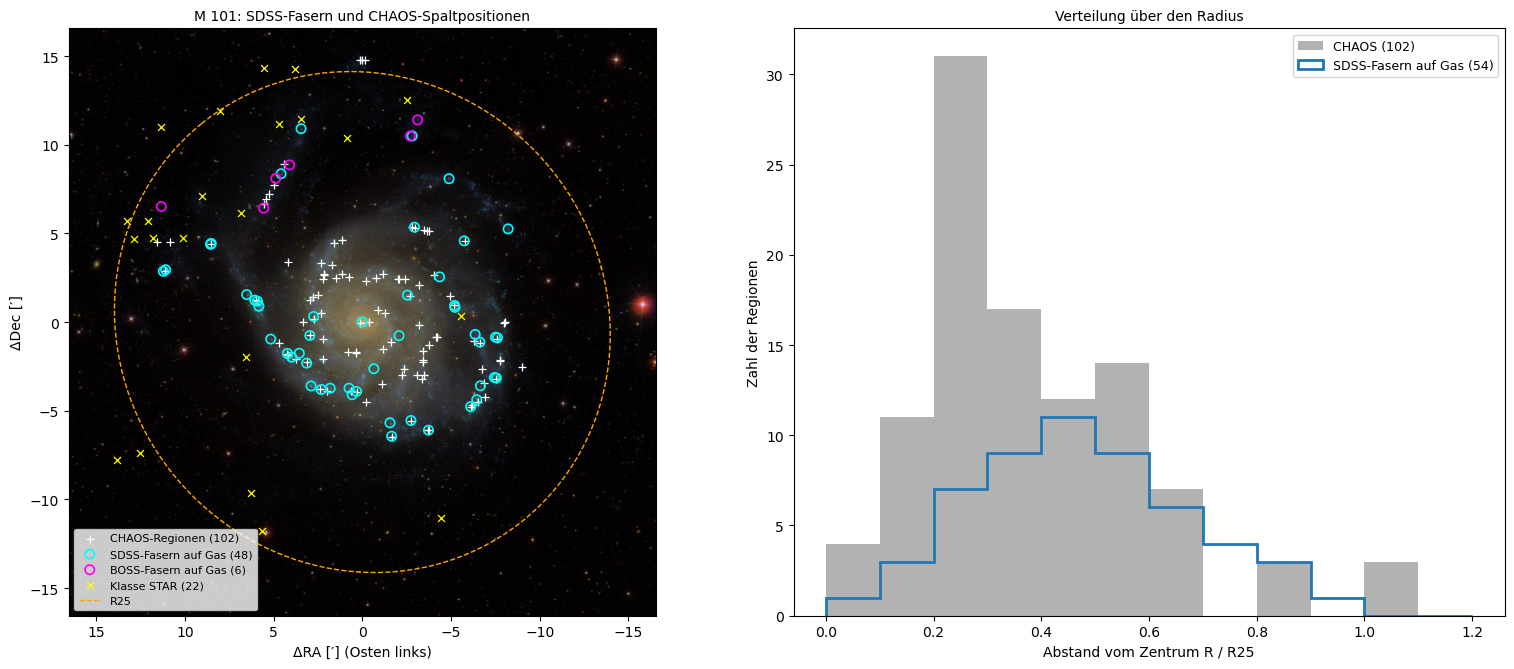

In [5]:
# CHAOS (Croxall et al. 2016): Positionen, Linienflüsse relativ zu Hβ, Temperaturen und Häufigkeiten
ch_pos = vizier_table("J/ApJ/830/4/table2")
ch_lin = vizier_table("J/ApJ/830/4/table3")
ch_ab = vizier_table("J/ApJ/830/4/table4").set_index("HIIid").apply(pd.to_numeric, errors="coerce")
ch_pos["RgR25"] = pd.to_numeric(ch_pos["RgR25"])
ch_lin["Flux"] = pd.to_numeric(ch_lin["Flux"], errors="coerce")
ch_lin.loc[ch_lin["f_Flux"] == "<", "Flux"] = np.nan                     # obere Grenzen sind keine Messungen
CH = ch_lin.assign(key=ch_lin["Species"] + ch_lin["lambda"]).pivot_table(index="HIIid", columns="key", values="Flux",
                                                                         aggfunc="first")
ch_c = SkyCoord(ch_pos["RAJ2000"], ch_pos["DEJ2000"], unit=(u.hourangle, u.deg))

# Das Zentrum steckt in den Namen: "NGC5457+7.2-3.8" liegt 7.2″ östlich und 3.8″ südlich davon
off = ch_pos["HIIid"].str.extract(r"NGC5457([+-][\d.]+)([+-][\d.]+)").astype(float)
RA0 = np.median(ch_c.ra.deg - off[0] / 3600 / np.cos(np.radians(ch_c.dec.deg)))
DEC0 = np.median(ch_c.dec.deg - off[1] / 3600)

def r_over_r25(ra, dec):
    # Abstand vom Zentrum in der Scheibe in Einheiten von R25 (Neigung und Lagewinkel wie bei CHAOS)
    x = (np.asarray(ra, float) - RA0) * np.cos(np.radians(DEC0)) * 3600
    y = (np.asarray(dec, float) - DEC0) * 3600
    pa, inc = np.radians(PA_DEG), np.radians(INC_DEG)
    return np.hypot(x * np.sin(pa) + y * np.cos(pa), (x * np.cos(pa) - y * np.sin(pa)) / np.cos(inc)) / R25_ARCSEC

ch_pos["R_own"] = r_over_r25(ch_c.ra.deg, ch_c.dec.deg)
KPC_PER_R25 = R25_ARCSEC / 206265 * D_MPC * 1e3

# SDSS: alle Spektren in einem Kasten der halben Breite R25 um das Zentrum, innerhalb von 600 km/s der Galaxie
r_deg = R25_ARCSEC / 3600
spec_list = sdss_query(f'''
SELECT s.specObjID, s.ra, s.dec, s.z, s.class, s.plate, s.mjd, s.fiberID, s.run2d, s.instrument, s.snMedian
FROM SpecObj AS s
WHERE s.ra BETWEEN {RA0 - r_deg / np.cos(np.radians(DEC0))} AND {RA0 + r_deg / np.cos(np.radians(DEC0))}
  AND s.dec BETWEEN {DEC0 - r_deg} AND {DEC0 + r_deg}
  AND s.z BETWEEN {(V_SYS - 600) / C_KMS} AND {(V_SYS + 600) / C_KMS}
ORDER BY s.snMedian DESC''')
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    hdus = SDSS.get_spectra(matches=spec_list, data_release=17)
SPEC = [dict(w=10 ** h[1].data["loglam"], f=h[1].data["flux"].astype(float), iv=h[1].data["ivar"].astype(float),
             wdisp=h[1].data["wdisp"].astype(float)) for h in hdus]
S = spec_list.to_pandas()
S["specObjID"] = spec_list["specObjID"].astype(str)
S["RR25"] = r_over_r25(S["ra"], S["dec"])
idx, sep, _ = SkyCoord(S["ra"].values * u.deg, S["dec"].values * u.deg).match_to_catalog_sky(ch_c)
S["chaos"] = np.where(sep.arcsec < 3, ch_pos["HIIid"].values[idx], None)
gas = (S["class"] == "GALAXY").values

# Farbbild aus SDSS
FOV = 2.3 * R25_ARCSEC
img = plt.imread(download([f"https://skyserver.sdss.org/dr17/SkyServerWS/ImgCutout/getjpeg?ra={RA0}&dec={DEC0}"
                           f"&scale={FOV / 1000:.4f}&width=1000&height=1000"], ASTRODATA / "sdss_m101.jpg"))

n_te = ch_ab["Te([OIII])1"].notna() | ch_ab["Te([NII])1"].notna() | ch_ab["Te([SIII])1"].notna()
print(f"Zentrum aus den CHAOS-Namen: RA {RA0:.5f}°, Dec {DEC0:.5f}°; R25 = {R25_ARCSEC / 60:.1f}′ = {KPC_PER_R25:.1f} kpc bei {D_MPC} Mpc")
print(f"Kontrolle: eigene Abstände R/R25 minus CHAOS: höchstens {np.abs(ch_pos['R_own'] - ch_pos['RgR25']).max():.4f}")
print(f"CHAOS: {len(ch_pos)} Regionen, {n_te.sum()} mit mindestens einer gemessenen Temperatur, {ch_ab['12+log(O/H)'].notna().sum()} mit O/H")
print(f"SDSS: {len(S)} Spektren; Klassen {S['class'].value_counts().to_dict()}; "
      f"Spektrographen {S['instrument'].value_counts().to_dict()}")
print(f"Fasern auf Gas: {gas.sum()} (SDSS {(gas & (S['instrument'] == 'SDSS')).sum()}, BOSS {(gas & (S['instrument'] == 'BOSS')).sum()}); "
      f"innerhalb von 3″ einer CHAOS-Region: {S.loc[gas, 'chaos'].notna().sum()}")

half = FOV / 2 / 60
dx = lambda ra: (np.asarray(ra, float) - RA0) * np.cos(np.radians(DEC0)) * 60
dy = lambda dec: (np.asarray(dec, float) - DEC0) * 60
fig, axes = plt.subplots(1, 2, figsize=(16, 6.8), gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]
ax.imshow(img, extent=[half, -half, -half, half])
ax.scatter(dx(ch_c.ra.deg), dy(ch_c.dec.deg), marker="+", s=30, c="white", lw=0.9, label=f"CHAOS-Regionen ({len(ch_pos)})")
for inst, col in [("SDSS", "cyan"), ("BOSS", "magenta")]:
    m = gas & (S["instrument"] == inst).values
    ax.scatter(dx(S.loc[m, "ra"]), dy(S.loc[m, "dec"]), s=45, facecolors="none", edgecolors=col, lw=1.2,
               label=f"{inst}-Fasern auf Gas ({m.sum()})")
ax.scatter(dx(S.loc[~gas, "ra"]), dy(S.loc[~gas, "dec"]), s=25, marker="x", c="yellow", lw=0.9, label=f"Klasse STAR ({(~gas).sum()})")
t = np.linspace(0, 2 * np.pi, 300)
pa, xm, ym = np.radians(PA_DEG), R25_ARCSEC / 60 * np.cos(t), R25_ARCSEC / 60 * np.cos(np.radians(INC_DEG)) * np.sin(t)
ax.plot(xm * np.sin(pa) + ym * np.cos(pa), xm * np.cos(pa) - ym * np.sin(pa), c="orange", ls="--", lw=1, label="R25")
ax.set_xlim(half, -half)
ax.set_ylim(-half, half)
ax.set_xlabel("ΔRA [′] (Osten links)")
ax.set_ylabel("ΔDec [′]")
ax.set_title("M 101: SDSS-Fasern und CHAOS-Spaltpositionen", fontsize=10)
ax.legend(fontsize=8, loc="lower left")
bins = np.arange(0, 1.25, 0.1)
axes[1].hist(ch_pos["RgR25"], bins=bins, color="grey", alpha=0.6, label=f"CHAOS ({len(ch_pos)})")
axes[1].hist(S.loc[gas, "RR25"], bins=bins, histtype="step", lw=2, color="tab:blue", label=f"SDSS-Fasern auf Gas ({gas.sum()})")
axes[1].set_xlabel("Abstand vom Zentrum R / R25")
axes[1].set_ylabel("Zahl der Regionen")
axes[1].set_title("Verteilung über den Radius", fontsize=10)
axes[1].legend(fontsize=9)
fig.tight_layout()
plt.show()

* Die **Ausgabe:** Das Zentrum aus den CHAOS-Namen liegt bei RA 210.80207°, Dec 54.34886°; R25 = 14.4′ sind bei 7.4 Mpc 31.0 kpc. Die eigenen Abstände R/R25 weichen höchstens um 0.002 von denen in der CHAOS-Tabelle ab, die Geometrie ist also dieselbe. CHAOS hat 102 Regionen, 74 mit mindestens einer gemessenen Temperatur und 77 mit O/H. Bei SDSS liegen 76 Spektren im Kasten: 54 auf Gas (48 vom SDSS-, 6 vom BOSS-Spektrographen) und 22 Vordergrundsterne.
* Das **linke Bild:** Die SDSS-Fasern (Kreise) und die CHAOS-Spalte (Kreuze) sitzen auf den blauen Knoten der Spiralarme, den H-II-Regionen. Die 6 BOSS-Fasern liegen alle im Norden. 14 Fasern liegen innerhalb von 3″ einer CHAOS-Position: dieselben Regionen, mit zwei Instrumenten gemessen (Schritt 12).
* Das **rechte Bild:** CHAOS hat die meisten Regionen zwischen 0.2 und 0.3 R25, die SDSS-Fasern verteilen sich gleichmäßiger bis 1.0 R25 und liegen im Mittel weiter außen. Für den Gradienten ist das günstig: Er wird über einen langen Hebel gemessen.

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-2"></a>

##### *2. Erster Blick auf die schwachen Linien*

Wie schwach sind die Temperaturlinien im Vergleich zu den starken Linien, und was passiert mit den hellsten Linien im Detektor? Vorher vorhersagen: Ist [O III] 4363 in der heißen, metallarmen Riesen-H-II-Region NGC 5471 höher oder niedriger als ein Zehntel von Hγ?

Gezeigt wird das rohe Spektrum der Faser, die CHAOS-Positionen in NGC 5471 am nächsten liegt, und vergrößert die Umgebung der vier Temperaturlinien. Die Ausgabe zählt maskierte Pixel im Kern der hellen Linien und vergleicht die Spitzenhöhen.

**Hintergrund & Fachbegriffe:**
- **NGC 5471:** eine der hellsten H-II-Regionen am Ostrand von M 101, etwa 25 kpc vom Zentrum, mit nur etwa einem Drittel der Sauerstoffhäufigkeit der Sonne (Schritt 11).
- **Maskierte Pixel:** Pixel mit inverser Varianz null; hier war der Detektor gesättigt, der Wert ist unbrauchbar.
- **Spitzenhöhe:** das höchste Pixel einer Linie über dem Kontinuum; nur ein grobes Maß, gemessen wird in Schritt 3.

Faser 1491914454806325248 (SDSS), 4.4″ von einer CHAOS-Position in NGC 5471, R/R25 = 0.82
  Hb       : 0 maskierte Pixel im Linienkern
  OIII5007 : 5 maskierte Pixel im Linienkern
  Ha       : 4 maskierte Pixel im Linienkern
  OIII4363 : 0 maskierte Pixel im Linienkern
Spitzenhöhe über dem Kontinuum relativ zu Hγ: OIII4363 0.225, NII5755 0.003, SIII6312 0.026, OII7320 0.026, OII7330 0.021


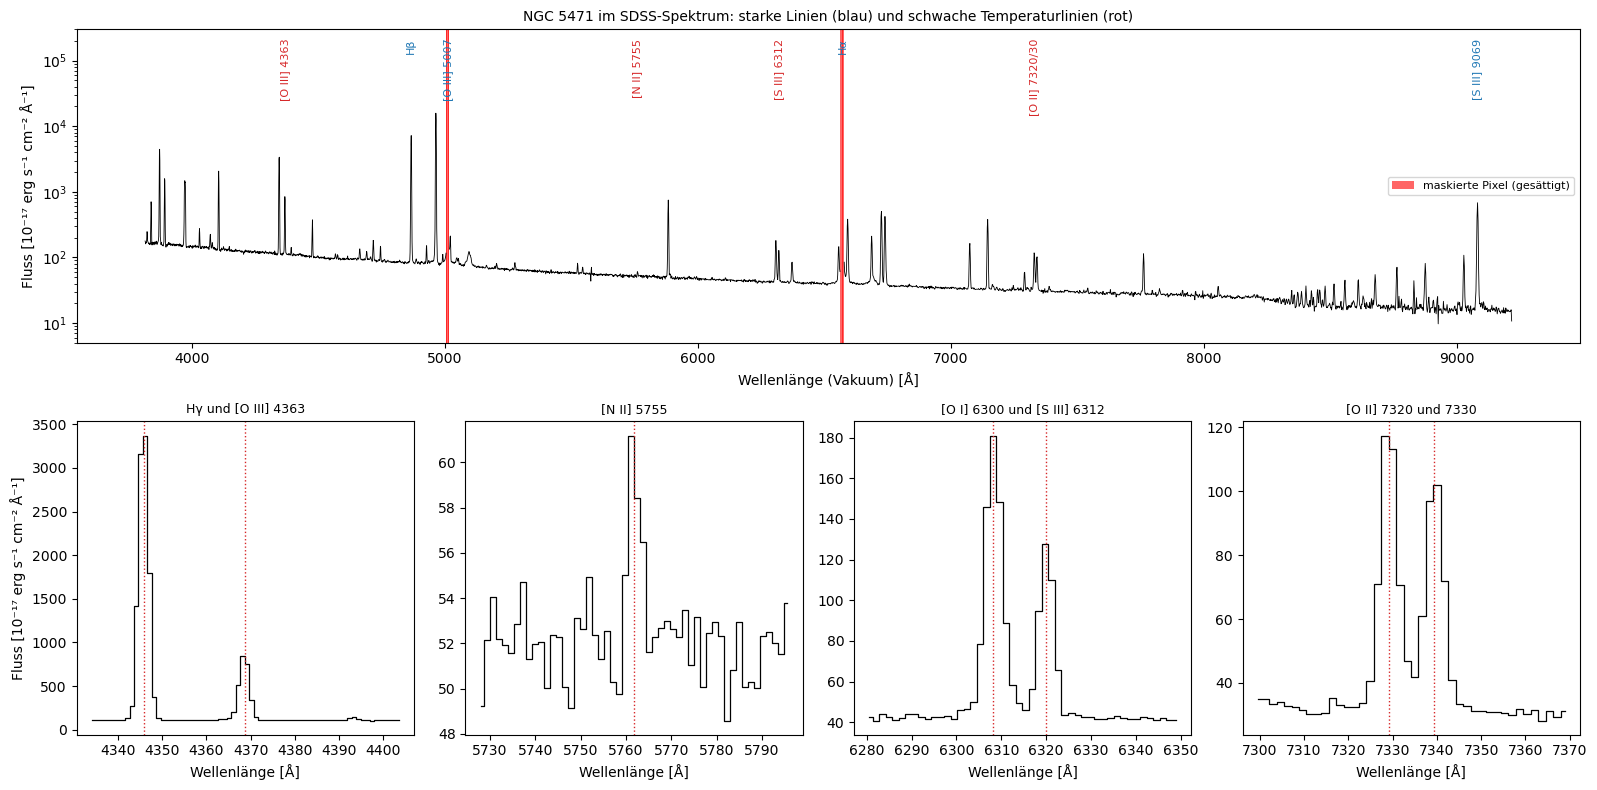

In [6]:
# Die Faser auf NGC 5471, der hellen, metallarmen Riesen-H-II-Region am Ostrand von M 101
n5471 = ch_pos[pd.to_numeric(ch_pos["NGC"], errors="coerce") == 5471]
c5471 = SkyCoord(n5471["RAJ2000"], n5471["DEJ2000"], unit=(u.hourangle, u.deg))
cs = SkyCoord(S["ra"].values * u.deg, S["dec"].values * u.deg)
dist = np.min([cs.separation(c).arcsec for c in c5471], axis=0)
I_SHOW = int(np.argmin(np.where(gas, dist, np.inf)))
sp, z_show = SPEC[I_SHOW], S.loc[I_SHOW, "z"]
masked = sp["iv"] <= 0
print(f"Faser {S.loc[I_SHOW, 'specObjID']} ({S.loc[I_SHOW, 'instrument']}), {dist[I_SHOW]:.1f}″ von einer CHAOS-Position in NGC 5471, "
      f"R/R25 = {S.loc[I_SHOW, 'RR25']:.2f}")
for n in ["Hb", "OIII5007", "Ha", "OIII4363"]:
    core = np.abs(sp["w"] - LINES[n] * (1 + z_show)) < 3
    print(f"  {n:9s}: {masked[core].sum()} maskierte Pixel im Linienkern")
def peak(n):
    # Höhe des höchsten Pixels über dem Median der Umgebung
    lam = LINES[n] * (1 + z_show)
    near, core = np.abs(sp["w"] - lam) < 30, np.abs(sp["w"] - lam) < 2.5
    return np.nanmax(np.where(core & ~masked, sp["f"], np.nan)) - np.median(sp["f"][near])
print("Spitzenhöhe über dem Kontinuum relativ zu Hγ: " + ", ".join(f"{n} {peak(n) / peak('Hg'):.3f}" for n in
      ["OIII4363", "NII5755", "SIII6312", "OII7320", "OII7330"]))

fig = plt.figure(figsize=(16, 8))
ax = fig.add_subplot(2, 1, 1)
ax.semilogy(sp["w"], np.where(masked, np.nan, sp["f"]), lw=0.6, c="k")
for k, w0 in enumerate(sp["w"][masked]):
    ax.axvspan(w0 - 1, w0 + 1, color="red", alpha=0.6, lw=0, label="maskierte Pixel (gesättigt)" if k == 0 else None)
for n, lab in [("OIII4363", "[O III] 4363"), ("Hb", "Hβ"), ("OIII5007", "[O III] 5007"), ("NII5755", "[N II] 5755"),
               ("SIII6312", "[S III] 6312"), ("Ha", "Hα"), ("OII7320", "[O II] 7320/30"), ("SIII9069", "[S III] 9069")]:
    weak = n in ("OIII4363", "NII5755", "SIII6312", "OII7320")
    ax.text(LINES[n] * (1 + z_show), 0.97, lab, rotation=90, fontsize=8, ha="center", va="top",
            color="tab:red" if weak else "tab:blue", transform=ax.get_xaxis_transform())
ax.set_ylim(5, 3e5)
ax.set_xlabel("Wellenlänge (Vakuum) [Å]")
ax.set_ylabel("Fluss [10⁻¹⁷ erg s⁻¹ cm⁻² Å⁻¹]")
ax.set_title("NGC 5471 im SDSS-Spektrum: starke Linien (blau) und schwache Temperaturlinien (rot)", fontsize=10)
ax.legend(fontsize=8, loc="center right")
zooms = [("Hγ und [O III] 4363", 4364.4, ["Hg", "OIII4363"]), ("[N II] 5755", 5756.2, ["NII5755"]),
         ("[O I] 6300 und [S III] 6312", 6308.0, ["OI6300", "SIII6312"]), ("[O II] 7320 und 7330", 7327.0, ["OII7320", "OII7330"])]
for k, (title, lam, names) in enumerate(zooms):
    ax = fig.add_subplot(2, 4, 5 + k)
    lo = lam * (1 + z_show)
    m = np.abs(sp["w"] - lo) < 35
    ax.step(sp["w"][m], np.where(masked[m], np.nan, sp["f"][m]), where="mid", lw=0.9, c="k")
    for n in names:
        ax.axvline(LINES[n] * (1 + z_show), c="tab:red", ls=":", lw=1)
    ax.set_xlabel("Wellenlänge [Å]")
    if k == 0:
        ax.set_ylabel("Fluss [10⁻¹⁷ erg s⁻¹ cm⁻² Å⁻¹]")
    ax.set_title(title, fontsize=9)
fig.tight_layout()
plt.show()

* Das **obere Bild** zeigt das rohe Spektrum der Faser auf NGC 5471 (4.4″ von einer CHAOS-Position, R/R25 = 0.82) in logarithmischer Skala. Die starken Linien Hβ, [O III] und [S III] 9069 ragen weit über das Kontinuum der Sterne. Bei [O III] 5007 (5 Pixel) und Hα (4 Pixel) fehlen die Werte im Kern ganz (rote Bänder): Der Detektor war gesättigt, die Pipeline hat die Pixel maskiert. Gerade die hellste Region hat also keine brauchbare 5007- und Hα-Linie.
* Die **unteren Bilder** zeigen die vier Temperaturlinien. [O III] 4363 ist neben Hγ deutlich, mit einer Spitzenhöhe von 0.23 der von Hγ: NGC 5471 ist heiß und metallarm. [N II] 5755 hebt sich kaum aus dem Rauschen (0.003 von Hγ), denn hier gibt es wenig Stickstoff. [S III] 6312 neben [O I] 6300 und das Dublett [O II] 7320/7330 sind klar (je 0.02 bis 0.03 von Hγ).
* Die Antwort auf die Vorhersage: 4363 ist höher als ein Zehntel von Hγ, ein Viertel. In metallreichen Regionen wird es dagegen hundertmal schwächer; deshalb braucht die Messung Lage und Breite aus den starken Linien (Schritt 3) und einen Ersatz für gesättigte Linien (Schritt 4).

[↑ Zurück zur Landkarte](#landkarte)

#### **Reduktion**

<a id="exp-3"></a>

##### *3. Linienfits mit fester Lage und Breite*

Lassen sich Linien mit einem Hundertstel der Höhe von Hγ zuverlässig messen, und wie oft erzeugt das Rauschen allein eine scheinbare Linie? Vorher vorhersagen: Wie viele der 540 Leermessungen sollten bei rein Gaußschem Rauschen $|\text{S/N}| > 3$ haben?

Jede Faser wird in elf Liniengruppen angepasst. Die Lage aller Linien folgt aus der Rotverschiebung der stärksten unmaskierten Linie; starke Gruppen (etwa Hγ mit 4363, [O I] 6300 mit [S III] 6312) teilen eine freie Breite, [N II] 5755 bekommt eine feste Breite aus den starken Linien und der Instrumentbreite (Theorie, Abschnitt 8). Danach wird dieselbe Messung an zehn Wellenlängen ohne Linie wiederholt.

**Hintergrund & Fachbegriffe:**
- **Instrumentbreite:** die Breite, die der Spektrograph einer unendlich schmalen Linie gibt; SDSS liefert sie Pixel für Pixel (`wdisp`). Die Linien der H-II-Regionen sind nur wenig breiter.
- **Leermessung:** ein Fit an einer Stelle ohne Linie; die Verteilung ihrer S/N zeigt, ob die Fehler stimmen.
- **Nachweis:** hier S/N ≥ 5 für die Temperaturlinien, S/N ≥ 3 für die starken Linien.

54 Fasern angepasst; Breite der Linien im Median 1.11-mal die Instrumentbreite
Leermessungen: 540, Mittel +0.05, Streuung 1.11 (robust 1.08); |S/N| > 3: 1.1% (Gauß: 0.3 %); S/N > 5: 0
Linie       gemessen  S/N > 3  S/N > 5
OIII4363          54       23       15
NII5755           54       17       10
SIII6312          54       26       21
OII7320           54       26       24
OII7330           54       26       23
SIII9069          53       34       32
SIII9532           6        1        0
OII3726            6        4        4


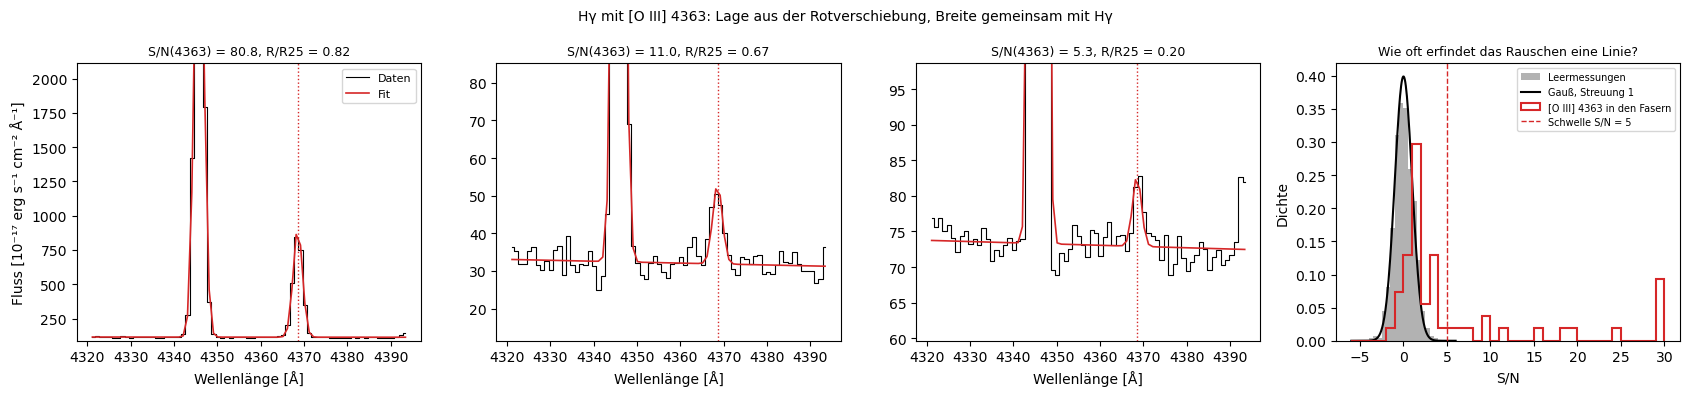

In [7]:
rows = []
for i in np.where(gas)[0]:
    rec = measure(SPEC[i], S.loc[i, "z"])
    rec.update(i_spec=i, **S.loc[i, ["specObjID", "ra", "dec", "instrument", "RR25", "chaos"]].to_dict())
    rows.append(rec)
L = pd.DataFrame(rows)
def sn(name):
    return (L[name] / L[name + "_e"]).fillna(0)

# Leermessung: dieselbe Messung an Stellen ohne Linie; das S/N sollte um 0 mit Streuung 1 liegen
EMPTY = [4400, 4560, 5300, 5600, 5800, 6200, 6400, 7200, 7450, 8000]
null = []
for _, r in L.iterrows():
    for lam in EMPTY:
        sp = SPEC[r["i_spec"]]
        try:
            res = fit_group(sp, [lam], r["z"], sig=r["width_ratio"] * inst_sigma(sp, lam * (1 + r["z"])))
        except (RuntimeError, ValueError):
            continue
        if res:
            null.append(res["flux"][lam] / res["err"][lam])
null = np.array(null)
mad = 1.4826 * np.median(np.abs(null - np.median(null)))
print(f"{len(L)} Fasern angepasst; Breite der Linien im Median {L['width_ratio'].median():.2f}-mal die Instrumentbreite")
print(f"Leermessungen: {len(null)}, Mittel {null.mean():+.2f}, Streuung {null.std():.2f} (robust {mad:.2f}); "
      f"|S/N| > 3: {np.mean(np.abs(null) > 3):.1%} (Gauß: 0.3 %); S/N > {SN_AUR:.0f}: {(null > SN_AUR).sum()}")
print(f"{'Linie':10s} {'gemessen':>9s} {'S/N > 3':>8s} {'S/N > 5':>8s}")
for n in ["OIII4363", "NII5755", "SIII6312", "OII7320", "OII7330", "SIII9069", "SIII9532", "OII3726"]:
    print(f"{n:10s} {L[n].notna().sum():9d} {(sn(n) > 3).sum():8d} {(sn(n) > 5).sum():8d}")

# drei Beispiele: starker, mittlerer und knapper Nachweis von [O III] 4363
order = sn("OIII4363").sort_values(ascending=False)
examples = [order.index[0], (order - 12).abs().idxmin(), (order - 5.5).abs().idxmin()]
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, j in zip(axes[:3], examples):
    r = L.loc[j]
    res = fit_group(SPEC[r["i_spec"]], ["Hg", "OIII4363"], r["z"])
    W, F, model = res["curve"]
    ax.step(W, F, where="mid", c="k", lw=0.8, label="Daten")
    ax.plot(W, model, c="tab:red", lw=1.2, label="Fit")
    ax.axvline(LINES["OIII4363"] * (1 + r["z"]), c="tab:red", ls=":", lw=1)
    h = res["flux"].get("OIII4363", 0) / (res["sigma"] * np.sqrt(2 * np.pi))      # Höhe der 4363-Linie
    noise = 1.4826 * np.median(np.abs(F - model))
    ax.set_ylim(np.median(F) - 6 * noise, np.median(F) + max(2.5 * h, 10 * noise))
    ax.set_title(f"S/N(4363) = {sn('OIII4363')[j]:.1f}, R/R25 = {r['RR25']:.2f}", fontsize=9)
    ax.set_xlabel("Wellenlänge [Å]")
axes[0].set_ylabel("Fluss [10⁻¹⁷ erg s⁻¹ cm⁻² Å⁻¹]")
axes[0].legend(fontsize=8)
xx = np.linspace(-6, 6, 200)
axes[3].hist(null, bins=np.arange(-6, 6.5, 0.5), density=True, color="grey", alpha=0.6, label="Leermessungen")
axes[3].plot(xx, np.exp(-xx ** 2 / 2) / np.sqrt(2 * np.pi), c="k", label="Gauß, Streuung 1")
axes[3].hist(sn("OIII4363").clip(-6, 30), bins=np.arange(-6, 30.5, 1), density=True, histtype="step", lw=1.5,
             color="tab:red", label="[O III] 4363 in den Fasern")
axes[3].axvline(SN_AUR, c="tab:red", ls="--", lw=1, label=f"Schwelle S/N = {SN_AUR:.0f}")
axes[3].set_xlabel("S/N")
axes[3].set_ylabel("Dichte")
axes[3].set_title("Wie oft erfindet das Rauschen eine Linie?", fontsize=9)
axes[3].legend(fontsize=7)
fig.suptitle("Hγ mit [O III] 4363: Lage aus der Rotverschiebung, Breite gemeinsam mit Hγ", fontsize=10)
fig.tight_layout()
plt.show()

* Die **ersten drei Bilder** zeigen Hγ mit [O III] 4363 für einen starken Nachweis (S/N 80.8, NGC 5471), einen mittleren (S/N 11.0) und einen knappen (S/N 5.3, nahe dem Zentrum bei R/R25 = 0.20). Auch beim knappen Nachweis trifft die rote Kurve eine Erhebung genau an der erwarteten Stelle; Lage und Breite waren vorgegeben, nur die Höhe war frei.
* Das **rechte Bild:** Die 540 Leermessungen an zehn Stellen ohne Linie (grau) folgen fast der Gaußkurve (Mittel +0.05, Streuung 1.11, robust 1.08). Die Fehler der Pipeline sind also etwa 10 % zu klein; 1.1 % der Leermessungen haben $|\text{S/N}| > 3$ statt der erwarteten 0.3 % (etwa 1.5 von 540), aber keine erreicht S/N 5. Die Schwelle S/N ≥ 5 für Temperaturen schließt zufällige Nachweise praktisch aus. Rot die 4363-Messungen der Fasern: eine Gruppe um null (keine Linie) und eine lange Flanke echter Nachweise.
* Die **Ausgabe:** Die Linien sind im Median 1.11-mal so breit wie die Instrumentbreite. Mit S/N > 5 gibt es [O III] 4363 in 15 Fasern, [N II] 5755 in 10, [S III] 6312 in 21, [O II] 7320/7330 in 23 bis 24 und [S III] 9069 in 32. [S III] 9532 und [O II] 3726 liegen nur im Bereich der 6 BOSS-Spektren (0 und 4 Nachweise), denn der SDSS-Spektrograph reicht nur von 3800 bis 9200 Å.

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-4"></a>

##### *4. Gesättigte Linien und Staub*

Wie ersetzt man gesättigte Linien, und wie viel Licht nimmt der Staub den Thermometern? Vorher vorhersagen: Schwächt der Staub [O III] 4363 stärker oder schwächer als [O III] 5007?

[O III] 4959 und 5007 kommen aus demselben Niveau; ihr Verhältnis legen A-Werte und Photonenenergien fest. Wo 5007 gesättigt ist, ersetzt 2.98 × 4959 die Linie. Die Rötung kommt aus Hα/Hβ, wo Hα gesättigt ist aus Hγ/Hβ (Theorie, Abschnitt 4). Danach ist jede Linie relativ zu Hβ entrötet.

**Hintergrund & Fachbegriffe:**
- **Balmer-Dekrement:** das Verhältnis zweier Balmer-Linien, hier Hα/Hβ oder Hγ/Hβ, als Maß für den Staub.
- **Äquivalentbreite** EW(Hβ): Fluss der Linie geteilt durch das Kontinuum darunter, in Å. Große Werte heißen: Das Gas überstrahlt das Sternlicht.

Theorie: 5007/4959 = 2.984; gemessen in 26 Fasern (S/N > 20): Median 3.000, Streuung 0.113
[O III] 5007 gesättigt und aus 4959 ersetzt: 3 Fasern; Hα gesättigt: 4
Staub aus Hα/Hβ: 43 Fasern, aus Hγ/Hβ: 4, ohne Staubwert: 7
E(B−V): Median 0.21 mag (16.–84. Perzentil 0.08 bis 0.47)
Hα/Hβ gegen Hγ/Hβ in 17 hellen Fasern: Unterschied im Median +0.057 mag, Streuung 0.159 mag
Lichtverlust durch Staub bei E(B−V) = 0.21: [O III] 4363 gegenüber 5007 um 12% stärker geschwächt, [S III] 6312 gegenüber 9069 um 21%


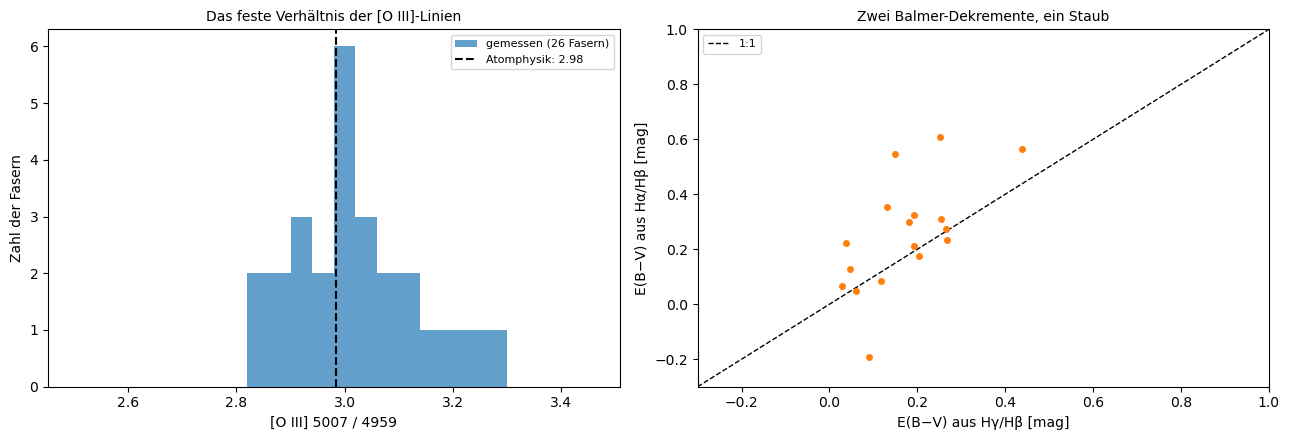

In [8]:
# [O III] 5007 aus 4959, wo 5007 gesättigt ist: beide Linien kommen vom selben Niveau (Theorie, Abschnitt 2)
R59 = O3.line(1e4, N_E, LINES["OIII5007"]) / O3.line(1e4, N_E, LINES["OIII4959"])
sat5007 = L["OIII5007"].isna() & L["OIII4959"].notna()
L["O5007"] = L["OIII5007"].where(~sat5007, R59 * L["OIII4959"])
L["O5007_e"] = L["OIII5007_e"].where(~sat5007, R59 * L["OIII4959_e"])
ok59 = (sn("OIII4959") > 20) & (sn("OIII5007") > 20)
r59 = L.loc[ok59, "OIII5007"] / L.loc[ok59, "OIII4959"]

# Staub: Hα/Hβ, wo Hα gesättigt ist Hγ/Hβ (Theorie, Abschnitt 4)
ebv_a = 2.5 / (K["Hb"] - K["Ha"]) * np.log10(L["Ha"] / L["Hb"] / HA_HB)
ebv_g = 2.5 / (K["Hb"] - K["Hg"]) * np.log10(L["Hg"] / L["Hb"] / HG_HB)
use_a = (sn("Ha") > SN_STRONG) & (sn("Hb") > SN_STRONG)
use_g = ~use_a & (sn("Hg") > SN_STRONG) & (sn("Hb") > SN_STRONG)
L["EBV_src"] = np.where(use_a, "Ha/Hb", np.where(use_g, "Hg/Hb", "-"))
L["EBV"] = np.where(use_a, ebv_a, np.where(use_g, ebv_g, np.nan)).clip(0, None)
L["EW_Hb"] = L["Hb"] / L["cont_Hb"]
bright = use_a & (sn("Hg") > 30)
d_ebv = (ebv_a - ebv_g)[bright]

def I(name, col=None):
    # entrötete Intensität relativ zu Hβ (Theorie, Abschnitt 4)
    return L[col or name] / L["Hb"] * 10 ** (0.4 * L["EBV"] * (K[name] - K["Hb"]))

print(f"Theorie: 5007/4959 = {R59:.3f}; gemessen in {ok59.sum()} Fasern (S/N > 20): Median {r59.median():.3f}, Streuung {r59.std():.3f}")
print(f"[O III] 5007 gesättigt und aus 4959 ersetzt: {sat5007.sum()} Fasern; Hα gesättigt: {(L['Ha'].isna() & L['Hb'].notna()).sum()}")
print(f"Staub aus Hα/Hβ: {use_a.sum()} Fasern, aus Hγ/Hβ: {use_g.sum()}, ohne Staubwert: {(~use_a & ~use_g).sum()}")
print(f"E(B−V): Median {L['EBV'].median():.2f} mag (16.–84. Perzentil {L['EBV'].quantile(0.16):.2f} bis {L['EBV'].quantile(0.84):.2f})")
print(f"Hα/Hβ gegen Hγ/Hβ in {bright.sum()} hellen Fasern: Unterschied im Median {d_ebv.median():+.3f} mag, Streuung {d_ebv.std():.3f} mag")
print(f"Lichtverlust durch Staub bei E(B−V) = {L['EBV'].median():.2f}: [O III] 4363 gegenüber 5007 um "
      f"{1 - 10 ** (-0.4 * L['EBV'].median() * (K['OIII4363'] - K['OIII5007'])):.0%} stärker geschwächt, "
      f"[S III] 6312 gegenüber 9069 um {1 - 10 ** (-0.4 * L['EBV'].median() * (K['SIII6312'] - K['SIII9069'])):.0%}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(r59, bins=np.arange(2.5, 3.5, 0.04), color="tab:blue", alpha=0.7, label=f"gemessen ({ok59.sum()} Fasern)")
axes[0].axvline(R59, c="k", ls="--", label=f"Atomphysik: {R59:.2f}")
axes[0].set_xlabel("[O III] 5007 / 4959")
axes[0].set_ylabel("Zahl der Fasern")
axes[0].set_title("Das feste Verhältnis der [O III]-Linien", fontsize=10)
axes[0].legend(fontsize=8)
lim = [-0.3, 1.0]
axes[1].errorbar(ebv_g[bright], ebv_a[bright], fmt="o", ms=4, c="tab:orange")
axes[1].plot(lim, lim, "k--", lw=1, label="1:1")
axes[1].set_xlim(lim)
axes[1].set_ylim(lim)
axes[1].set_xlabel("E(B−V) aus Hγ/Hβ [mag]")
axes[1].set_ylabel("E(B−V) aus Hα/Hβ [mag]")
axes[1].set_title("Zwei Balmer-Dekremente, ein Staub", fontsize=10)
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

* Das **linke Bild:** In 26 Fasern mit S/N > 20 ist [O III] 5007/4959 im Median 3.00 (Streuung 0.11), die Atomphysik sagt 2.98. In 3 Fasern ist 5007 gesättigt und wird durch 2.98 × 4959 ersetzt; in 4 Fasern ist Hα gesättigt.
* Das **rechte Bild:** E(B−V) aus Hγ/Hβ gegen E(B−V) aus Hα/Hβ in 17 hellen Fasern. Im Mittel stimmen beide (Unterschied +0.06 mag), aber Hγ/Hβ streut stark (0.16 mag): Hγ und Hβ liegen nah beieinander, ihr Verhältnis ändert sich mit dem Staub wenig, und kleine Messfehler werden zu großen Fehlern im Staub. Hγ/Hβ dient deshalb nur dort, wo Hα gesättigt ist (4 Fasern); 43 Fasern nehmen Hα/Hβ, 7 bleiben ohne Staubwert.
* Die **Ausgabe:** E(B−V) ist im Median 0.21 mag (0.08 bis 0.47). Dabei schwächt der Staub 4363 um 12 % mehr als 5007 und 6312 um 21 % mehr als 9069. Ohne Entrötung käme T[O III] bei 10 000 K um etwa 400 K zu niedrig heraus. Die Antwort auf die Vorhersage: 4363 wird stärker geschwächt, weil es blauer ist.

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-5"></a>

##### *5. Die Dichte*

Wie dicht ist das Gas, und wie genau muss man die Dichte kennen, um die Temperatur zu messen? Vorher vorhersagen: Ändert sich die abgeleitete T[O III] um mehr oder weniger als 1 %, wenn man 1000 statt 100 Elektronen pro cm³ annimmt?

Das eigene Atom rechnet das [S II]-Verhältnis als Funktion der Dichte; die gemessene Verteilung ergibt $n_e$. Dann die Gegenprobe: Für Gas mit 10 000 K und 100 cm⁻³ wird jedes Thermometer mit einer falschen Dichte ausgewertet.

**Hintergrund & Fachbegriffe:**
- **Grenzfall dünnes Gas:** weit unter der kritischen Dichte; das [S II]-Verhältnis hängt dann nur noch von den statistischen Gewichten ab (1.45).
- **Angenommene Dichte:** CHAOS nimmt für die meisten Regionen 100 cm⁻³; dasselbe tut dieses Notebook (`N_E`).

[S II] 6717/6731 in 50 Fasern: Median 1.377 (16.–84. Perzentil 1.27 bis 1.45); Grenzwert für dünnes Gas 1.453
  -> n_e ≈ 60 cm⁻³ aus dem Median, 6 bis 161 cm⁻³ aus den Perzentilen; 14% liegen über dem Grenzwert


[O III]: angenommene Dichte 10 statt 100 cm⁻³ -> T = 10000 K, 1000 cm⁻³ -> 9992 K (wahr 10 000 K)


[N II]: angenommene Dichte 10 statt 100 cm⁻³ -> T = 10146 K, 1000 cm⁻³ -> 9928 K (wahr 10 000 K)


[S III]: angenommene Dichte 10 statt 100 cm⁻³ -> T = 10001 K, 1000 cm⁻³ -> 9986 K (wahr 10 000 K)


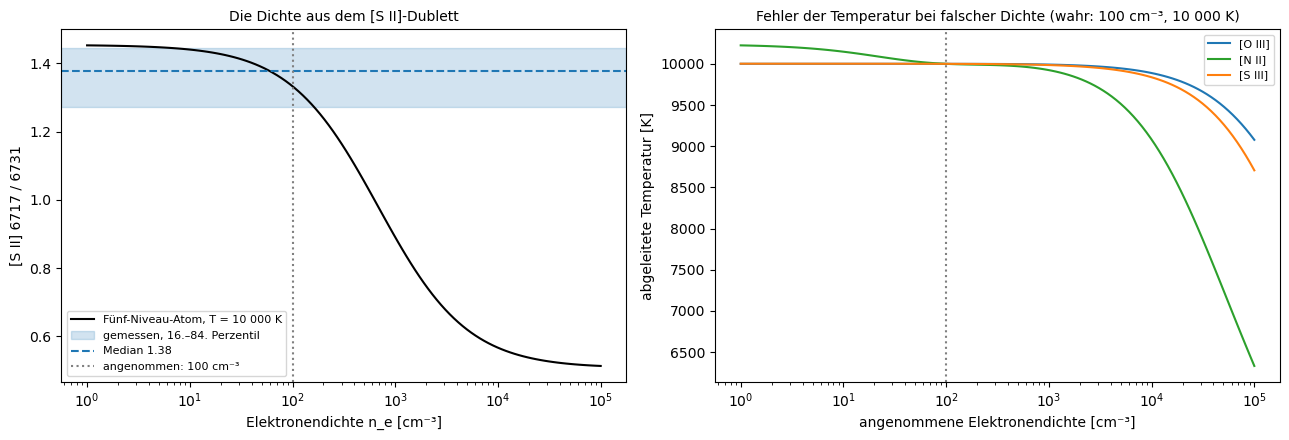

In [9]:
ne_grid = np.logspace(0, 5, 120)
R_s2 = np.array([S2.line(1e4, n, LINES["SII6717"]) / S2.line(1e4, n, LINES["SII6731"]) for n in ne_grid])
R_meas = (L["SII6717"] / L["SII6731"])[(sn("SII6717") > SN_STRONG) & (sn("SII6731") > SN_STRONG)]
R_lim = R_s2[0]
def ne_of(R):
    return np.interp(R, R_s2[::-1], ne_grid[::-1]) if R < R_lim else np.nan
print(f"[S II] 6717/6731 in {len(R_meas)} Fasern: Median {R_meas.median():.3f} (16.–84. Perzentil {R_meas.quantile(0.16):.2f} "
      f"bis {R_meas.quantile(0.84):.2f}); Grenzwert für dünnes Gas {R_lim:.3f}")
print(f"  -> n_e ≈ {ne_of(R_meas.median()):.0f} cm⁻³ aus dem Median, {ne_of(R_meas.quantile(0.84)):.0f} bis "
      f"{ne_of(R_meas.quantile(0.16)):.0f} cm⁻³ aus den Perzentilen; {np.mean(R_meas > R_lim):.0%} liegen über dem Grenzwert")

# Wie stark hängen die Thermometer von der Dichte ab? Temperatur, die man bei falscher Dichte erhielte
def ratio(atom, up, lo_pair, T, ne):
    return atom.line(T, ne, LINES[up]) / sum(atom.line(T, ne, LINES[l]) for l in lo_pair)
THERMO = {"[O III]": (O3, "OIII4363", ["OIII4959", "OIII5007"], "tab:blue"), "[N II]": (N2, "NII5755", ["NII6548", "NII6584"], "tab:green"),
          "[S III]": (S3, "SIII6312", ["SIII9069", "SIII9532"], "tab:orange")}
T_true = 1e4
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].semilogx(ne_grid, R_s2, c="k", label="Fünf-Niveau-Atom, T = 10 000 K")
axes[0].axhspan(R_meas.quantile(0.16), R_meas.quantile(0.84), color="tab:blue", alpha=0.2, label="gemessen, 16.–84. Perzentil")
axes[0].axhline(R_meas.median(), c="tab:blue", ls="--", label=f"Median {R_meas.median():.2f}")
axes[0].axvline(N_E, c="grey", ls=":", label=f"angenommen: {N_E:.0f} cm⁻³")
axes[0].set_xlabel("Elektronendichte n_e [cm⁻³]")
axes[0].set_ylabel("[S II] 6717 / 6731")
axes[0].set_title("Die Dichte aus dem [S II]-Dublett", fontsize=10)
axes[0].legend(fontsize=8)
for name, (atom, up, lo_pair, col) in THERMO.items():
    R_ref = ratio(atom, up, lo_pair, T_true, N_E)
    T_wrong = []
    for n in ne_grid:
        try:
            T_wrong.append(brentq(lambda T: ratio(atom, up, lo_pair, T, n) - R_ref, 3000, 40000))
        except ValueError:                                  # bei sehr hoher Dichte keine Lösung im Bereich
            T_wrong.append(np.nan)
    axes[1].semilogx(ne_grid, np.array(T_wrong), c=col, label=name)
    i1, i2 = np.argmin(np.abs(ne_grid - 10)), np.argmin(np.abs(ne_grid - 1000))
    print(f"{name}: angenommene Dichte 10 statt 100 cm⁻³ -> T = {T_wrong[i1]:.0f} K, 1000 cm⁻³ -> {T_wrong[i2]:.0f} K (wahr 10 000 K)")
axes[1].axvline(N_E, c="grey", ls=":")
axes[1].set_xlabel("angenommene Elektronendichte [cm⁻³]")
axes[1].set_ylabel("abgeleitete Temperatur [K]")
axes[1].set_title(f"Fehler der Temperatur bei falscher Dichte (wahr: {N_E:.0f} cm⁻³, 10 000 K)", fontsize=10)
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

* Das **linke Bild:** Das [S II]-Verhältnis aus dem eigenen Atom (schwarz) fällt von 1.45 im dünnen Gas auf 0.5 im dichten. Gemessen ist es im Median 1.38 in 50 Fasern (16.–84. Perzentil 1.27 bis 1.45), also $n_e \approx 60$ cm⁻³ (6 bis 160 cm⁻³ aus den Perzentilen). 14 % der Fasern liegen über dem Grenzwert 1.45; das ist Rauschen. Das Gas ist dünn, die Annahme von 100 cm⁻³ wie bei CHAOS passt.
* Das **rechte Bild:** Welche Temperatur käme heraus, wenn das Gas 100 cm⁻³ und 10 000 K hat, man aber eine andere Dichte annimmt? Bis 1000 cm⁻³ ändern sich alle drei Thermometer um weniger als 1 % ([O III] 9992 K, [N II] 9928 K, [S III] 9986 K). Erst über $10^4$ cm⁻³ fällt T[N II] deutlich ab, weil die kritische Dichte von ¹D bei N⁺ mit etwa $9\cdot10^4$ cm⁻³ am niedrigsten ist (bei O²⁺ $7\cdot10^5$ cm⁻³).
* Für die Temperaturen ist die genaue Dichte also unwichtig. Für O⁺ aus [O II] 7320/7330 gilt das nicht ganz, weil die ²D-Niveaus von O⁺ schon bei $10^3$ cm⁻³ abgeregt werden (Variation 2).

[↑ Zurück zur Landkarte](#landkarte)

#### **Eigene Messung**

<a id="exp-6"></a>

##### *6. Das Atom als Thermometer*

Liefert das selbst gelöste Fünf-Niveau-Atom dieselben Temperaturen wie CHAOS, wenn es dieselben Linienverhältnisse bekommt? Vorher vorhersagen: Um wie viel muss die Temperatur steigen, damit sich 4363/(4959 + 5007) verdoppelt?

Für jedes Thermometer wird das Linienverhältnis zwischen 5000 und 25 000 K tabelliert (Theorie, Abschnitt 3); ein gemessenes Verhältnis wird durch Interpolation zur Temperatur. Prüfung: Die entröteten CHAOS-Linien gehen durch dieselbe Tabelle, das Ergebnis wird mit den Temperaturen von CHAOS verglichen.

**Hintergrund & Fachbegriffe:**
- **Thermometer-Tabelle:** Weil das Verhältnis mit $T$ monoton steigt, ist die Umkehrung eindeutig.
- **Tellurische Absorption:** Wasserdampf und Sauerstoff der Erdatmosphäre schlucken Licht in Banden, etwa um 9300 bis 9600 Å, wo [S III] 9532 liegt.

[O III] (4959+5007)/4363 bei 10 000 K: Fünf-Niveau-Atom 204, Osterbrock & Ferland 212; bei 8000 K 462, bei 13 000 K 96
TO3 eigen minus CHAOS: 48 Regionen, Median -19 K, Streuung 22 K
TN2 eigen minus CHAOS: 39 Regionen, Median -102 K, Streuung 66 K
TS3 eigen minus CHAOS: 56 Regionen, Median +6 K, Streuung 117 K
T[S III] nur aus 9069 (9532 aus der Theorie, 2.47 × 9069): Median -82 K, Streuung 577 K; gemessen 9532/9069 bei CHAOS: Median 2.41, 16.–84. Perzentil 2.06 bis 3.32


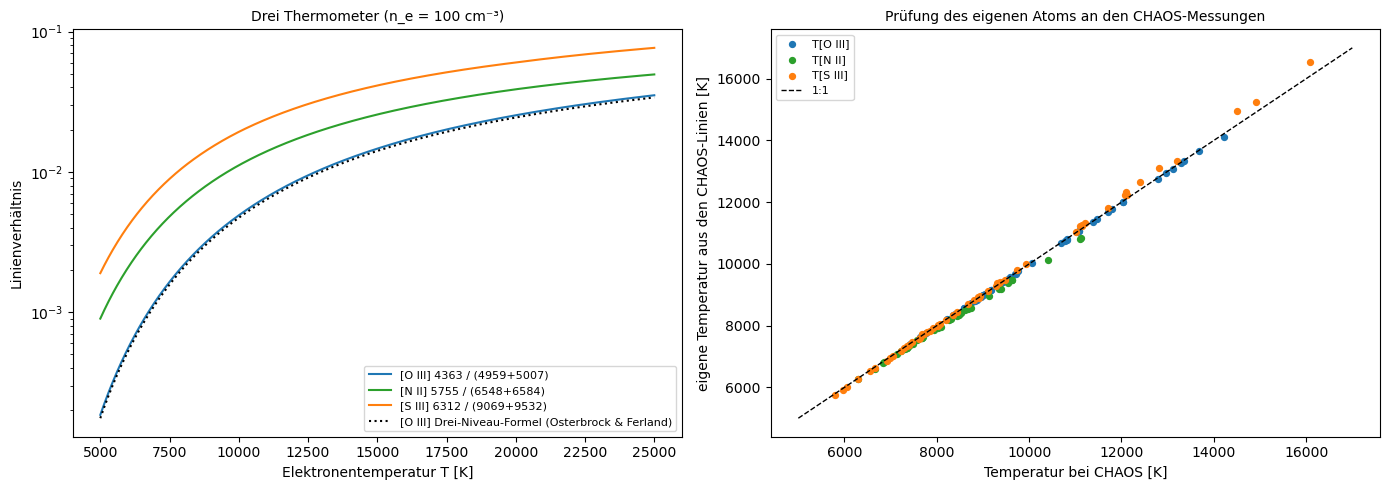

In [10]:
# Thermometer als Tabellen: Linienverhältnis gegen Temperatur bei N_E (Theorie, Abschnitt 3)
TG = np.arange(5000.0, 25001.0, 25.0)
def table(atom, up, lo_list):
    return np.array([atom.line(T, N_E, LINES[up], tol(up)) / sum(atom.line(T, N_E, LINES[l], tol(l)) for l in lo_list) for T in TG])
RATIO = {"O3": table(O3, "OIII4363", ["OIII4959", "OIII5007"]), "N2": table(N2, "NII5755", ["NII6548", "NII6584"]),
         "S3": table(S3, "SIII6312", ["SIII9069", "SIII9532"])}
def T_from(kind, R):
    return np.interp(R, RATIO[kind], TG, left=np.nan, right=np.nan)  # das Verhältnis steigt mit T

# Vereinfachte Formel aus dem Drei-Niveau-Bild (Osterbrock & Ferland 2006, Gl. 5.4)
of = 1 / (7.90 * np.exp(3.29e4 / TG))
i10 = np.argmin(np.abs(TG - 1e4))
print(f"[O III] (4959+5007)/4363 bei 10 000 K: Fünf-Niveau-Atom {1 / RATIO['O3'][i10]:.0f}, "
      f"Osterbrock & Ferland {1 / of[i10]:.0f}; bei 8000 K {1 / RATIO['O3'][np.argmin(np.abs(TG - 8000))]:.0f}, "
      f"bei 13 000 K {1 / RATIO['O3'][np.argmin(np.abs(TG - 13000))]:.0f}")

# Prüfung: aus den CHAOS-Linienverhältnissen die Temperatur rechnen und mit der von CHAOS vergleichen
ch_T = pd.DataFrame(index=CH.index)
ch_T["O3"] = T_from("O3", CH["[OIII]4363"] / (CH["[OIII]4959"] + CH["[OIII]5007"]))
ch_T["N2"] = T_from("N2", CH["[NII]5755"] / (CH["[NII]6548"] + CH["[NII]6583"]))
ch_T["S3"] = T_from("S3", CH["[SIII]6312"] / (CH["[SIII]9069"] + CH["[SIII]9531"]))
CHT = {"O3": "Te([OIII])1", "N2": "Te([NII])1", "S3": "Te([SIII])1"}
r95 = S3.line(1e4, N_E, LINES["SIII9532"]) / S3.line(1e4, N_E, LINES["SIII9069"])
ch_T["S3_9069"] = T_from("S3", CH["[SIII]6312"] / (CH["[SIII]9069"] * (1 + r95)))
for kind, col in CHT.items():
    d = (ch_T[kind] - ch_ab[col].reindex(ch_T.index)).dropna()
    print(f"T{kind} eigen minus CHAOS: {len(d)} Regionen, Median {d.median():+.0f} K, Streuung {d.std():.0f} K")
d = (ch_T["S3_9069"] - ch_ab["Te([SIII])1"].reindex(ch_T.index)).dropna()
obs95 = (CH["[SIII]9531"] / CH["[SIII]9069"]).dropna()
print(f"T[S III] nur aus 9069 (9532 aus der Theorie, {r95:.2f} × 9069): Median {d.median():+.0f} K, Streuung {d.std():.0f} K; "
      f"gemessen 9532/9069 bei CHAOS: Median {obs95.median():.2f}, 16.–84. Perzentil {obs95.quantile(0.16):.2f} bis {obs95.quantile(0.84):.2f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for kind, lab, c in [("O3", "[O III] 4363 / (4959+5007)", "tab:blue"), ("N2", "[N II] 5755 / (6548+6584)", "tab:green"),
                     ("S3", "[S III] 6312 / (9069+9532)", "tab:orange")]:
    axes[0].semilogy(TG, RATIO[kind], c=c, label=lab)
axes[0].semilogy(TG, of, "k:", label="[O III] Drei-Niveau-Formel (Osterbrock & Ferland)")
axes[0].set_xlabel("Elektronentemperatur T [K]")
axes[0].set_ylabel("Linienverhältnis")
axes[0].set_title(f"Drei Thermometer (n_e = {N_E:.0f} cm⁻³)", fontsize=10)
axes[0].legend(fontsize=8)
for kind, c in [("O3", "tab:blue"), ("N2", "tab:green"), ("S3", "tab:orange")]:
    axes[1].scatter(ch_ab[CHT[kind]].reindex(ch_T.index), ch_T[kind], s=18, c=c, label=f"T{kind}".replace("TO3", "T[O III]")
                    .replace("TN2", "T[N II]").replace("TS3", "T[S III]"))
axes[1].plot([5000, 17000], [5000, 17000], "k--", lw=1, label="1:1")
axes[1].set_xlabel("Temperatur bei CHAOS [K]")
axes[1].set_ylabel("eigene Temperatur aus den CHAOS-Linien [K]")
axes[1].set_title("Prüfung des eigenen Atoms an den CHAOS-Messungen", fontsize=10)
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

* Das **linke Bild:** Die drei Thermometer aus dem Fünf-Niveau-Atom steigen alle mit der Temperatur, [O III] am steilsten. (4959 + 5007)/4363 ist 462 bei 8000 K, 204 bei 10 000 K und 96 bei 13 000 K; für die Verdopplung des Verhältnisses reichen also gut 20 % mehr Temperatur. Die gepunktete Drei-Niveau-Formel von Osterbrock & Ferland liegt 4 % daneben (212 statt 204 bei 10 000 K), weil sie ältere Atomdaten benutzt; in der Temperatur macht das gut 100 K.
* Das **rechte Bild:** Gibt man dem eigenen Atom die entröteten Linien von CHAOS, kommen fast dieselben Temperaturen heraus wie bei CHAOS: T[O III] im Median −19 K (Streuung 22 K, 48 Regionen), T[N II] −102 K (66 K, 39 Regionen), T[S III] +6 K (117 K, 56 Regionen). Der kleine Versatz bei [N II] kommt vermutlich von anderen Atomdaten; CHAOS nutzt die von Berg et al. (2015).
* Die **Ausgabe** zeigt auch eine Falle: Nimmt man für [S III] nur 9069 und setzt 9532 = 2.47 × 9069 aus der Theorie, streut T[S III] um 577 K statt 117 K. Bei CHAOS schwankt das gemessene 9532/9069 zwischen 2.06 und 3.32 (Median 2.41), weil Wasserdampf der Erdatmosphäre Teile der Linien schluckt. Die SDSS-Fasern enden bei 9200 Å und haben nur 9069; ihre T[S III] ist darum unsicherer als die beiden anderen Thermometer.

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-7"></a>

##### *7. Die Temperaturen der Regionen*

Wie heiß ist das Gas in den einzelnen Regionen von M 101, und wie ändert sich die Temperatur mit dem Abstand vom Zentrum? Vorher vorhersagen: Ist das Gas innen, wo mehr Sauerstoff ist, heißer oder kälter als außen?

Für jede Faser werden die Linienflüsse 500-mal aus ihren Fehlern gezogen; jede Ziehung durchläuft Entrötung und Thermometer. Median und 16./84. Perzentil der Temperaturen sind Wert und Fehler. Nur Temperaturlinien mit S/N ≥ 5 gehen ein. Eine Gerade durch T[O III] mit innerer Streuung beschreibt den Verlauf.

**Hintergrund & Fachbegriffe:**
- **Monte-Carlo-Fehlerfortpflanzung:** Statt Ableitungen von Formeln rechnet man das Ergebnis für viele zufällig gestörte Eingaben; die Streuung der Ergebnisse ist der Fehler. Das funktioniert auch bei der stark nichtlinearen Umkehrung der Thermometer.
- **Innere Streuung:** Streuung um die Gerade, die die Messfehler nicht erklären; echte Unterschiede zwischen Regionen oder unbekannte Fehler.

T_O3: 14 Fasern, 8356 bis 13109 K, Median 10468 K, Fehler im Median ±192 K
T_N2:  9 Fasern, 7442 bis 13399 K, Median 8605 K, Fehler im Median ±452 K
T_S3: 18 Fasern, 7455 bis 13797 K, Median 10168 K, Fehler im Median ±320 K
Gerade durch T[O III]: 6690 ± 700 K im Zentrum, +7081 ± 1215 K pro R25, innere Streuung 686 K
  CHAOS Te([OIII])1: 49 Regionen, 7420 bis 14220 K
  CHAOS Te([NII])1: 46 Regionen, 6300 bis 11200 K
  CHAOS Te([SIII])1: 59 Regionen, 5800 bis 16080 K


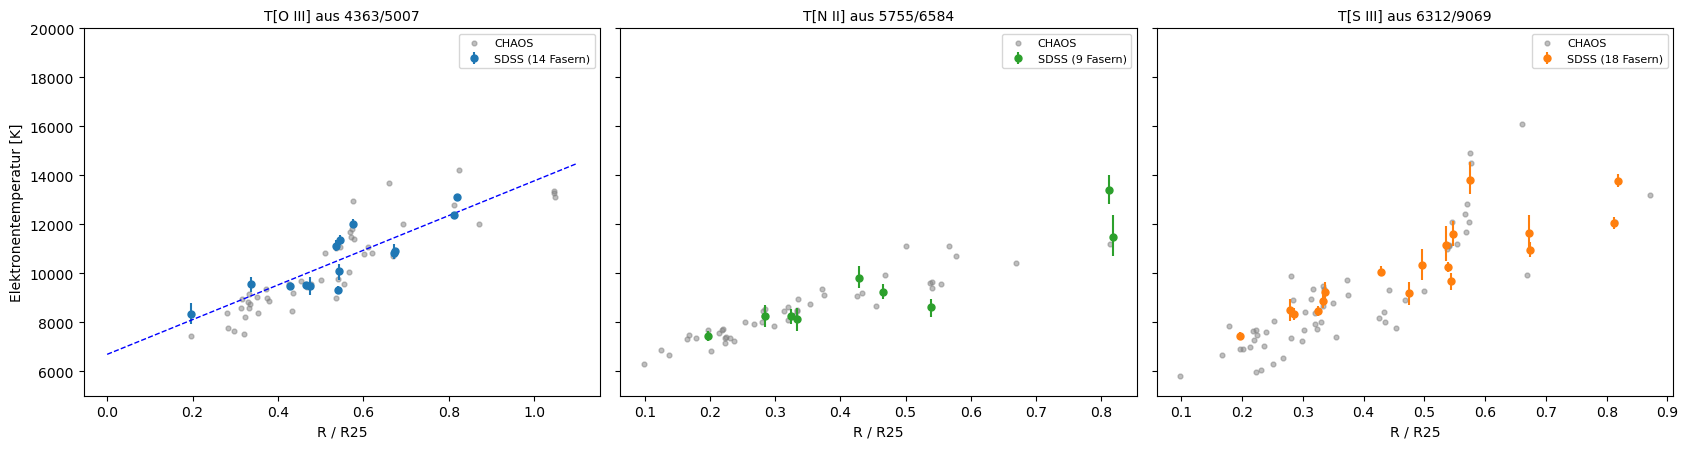

In [11]:
AURORAL = ["OIII4363", "NII5755", "SIII6312", "OII7320", "OII7330"]
STRONG = ["Ha", "Hb", "Hg", "O5007", "NII6584", "SIII9069", "OII3726", "OII3729"]
r_n2 = N2.line(1e4, N_E, LINES["NII6584"]) / N2.line(1e4, N_E, LINES["NII6548"])     # festes Verhältnis 6584/6548

def draw(row, n=N_MC):
    # Linienflüsse einer Faser n-mal aus ihren Fehlern ziehen; nur Nachweise über der Schwelle
    s = {}
    for k in STRONG + AURORAL:
        if np.isfinite(row.get(k, np.nan)) and row[k] / row[k + "_e"] > (SN_AUR if k in AURORAL else SN_STRONG):
            s[k] = row[k] + row[k + "_e"] * rng.standard_normal(n)
    if not ("OII7320" in s and "OII7330" in s):
        s.pop("OII7320", None)
        s.pop("OII7330", None)
    return s

def temperatures(s, src):
    # Staub und Temperaturen aus einer Ziehung (Theorie, Abschnitte 3 und 4)
    if src == "Ha/Hb" and "Ha" in s:
        ebv = 2.5 / (K["Hb"] - K["Ha"]) * np.log10(s["Ha"] / s["Hb"] / HA_HB)
    elif "Hg" in s:
        ebv = 2.5 / (K["Hb"] - K["Hg"]) * np.log10(s["Hg"] / s["Hb"] / HG_HB)
    else:
        return None
    ebv = np.clip(ebv, 0, None)
    Ii = lambda name, f: f / s["Hb"] * 10 ** (0.4 * ebv * (K[name] - K["Hb"]))
    out = {"EBV": ebv, "I5007": Ii("OIII5007", s["O5007"])}
    if "OIII4363" in s:
        out["T_O3"] = T_from("O3", Ii("OIII4363", s["OIII4363"]) / (out["I5007"] * (1 + 1 / R59)))
    if "NII5755" in s and "NII6584" in s:
        out["T_N2"] = T_from("N2", Ii("NII5755", s["NII5755"]) / (Ii("NII6584", s["NII6584"]) * (1 + 1 / r_n2)))
    if "SIII6312" in s and "SIII9069" in s:
        out["T_S3"] = T_from("S3", Ii("SIII6312", s["SIII6312"]) / (Ii("SIII9069", s["SIII9069"]) * (1 + r95)))
    if "OII7320" in s:
        out["I7325"] = Ii("OII7320", s["OII7320"] + s["OII7330"])
    if "OII3726" in s and "OII3729" in s:
        out["I3727"] = Ii("OII3726", s["OII3726"] + s["OII3729"])
    return out

def fit_gradient(R, y, e):
    # Gerade mit zusätzlicher innerer Streuung σ_int, so dass χ² pro Freiheitsgrad 1 ist
    R, y, e = map(np.asarray, (R, y, e))
    def chi2_red(s_int):
        w = 1 / (e ** 2 + s_int ** 2)
        p = np.polyfit(R, y, 1, w=np.sqrt(w))
        return np.sum(w * (y - np.polyval(p, R)) ** 2) / (len(y) - 2) - 1
    s_int = brentq(chi2_red, 0, 5 * np.std(y)) if chi2_red(0) > 0 else 0.0
    w = 1 / (e ** 2 + s_int ** 2)
    p, cov = np.polyfit(R, y, 1, w=np.sqrt(w), cov="unscaled")
    return p, np.sqrt(np.diag(cov)), s_int

DRAWS = {}
for j, r in L.iterrows():
    if r["EBV_src"] == "-" or not np.isfinite(r.get("O5007", np.nan)):
        continue
    s = draw(r)
    if "Hb" not in s or "O5007" not in s:
        continue
    t = temperatures(s, r["EBV_src"])
    if t:
        DRAWS[j] = t
for kind in ["T_O3", "T_N2", "T_S3"]:
    med, lo, hi = np.full(len(L), np.nan), np.full(len(L), np.nan), np.full(len(L), np.nan)
    for j, t in DRAWS.items():
        if kind in t and np.isfinite(t[kind]).mean() > 0.9:
            med[j], lo[j], hi[j] = np.nanpercentile(t[kind], [50, 16, 84])
    L[kind], L[kind + "_lo"], L[kind + "_hi"] = med, lo, hi
    e = (L[kind + "_hi"] - L[kind + "_lo"]) / 2
    print(f"{kind}: {L[kind].notna().sum():2d} Fasern, {L[kind].min():.0f} bis {L[kind].max():.0f} K, Median {L[kind].median():.0f} K, "
          f"Fehler im Median ±{e.median():.0f} K")
m = L["T_O3"].notna()
(sl, ic), (dsl, dic), s_int = fit_gradient(L.loc[m, "RR25"], L.loc[m, "T_O3"], (L.loc[m, "T_O3_hi"] - L.loc[m, "T_O3_lo"]) / 2)
print(f"Gerade durch T[O III]: {ic:.0f} ± {dic:.0f} K im Zentrum, {sl:+.0f} ± {dsl:.0f} K pro R25, innere Streuung {s_int:.0f} K")
ch_m = ch_ab.reindex(ch_pos["HIIid"].values)
ch_m.index = ch_pos.index
for kind, col in CHT.items():
    mm = ch_m[col].notna()
    print(f"  CHAOS {col}: {mm.sum()} Regionen, {ch_m.loc[mm, col].min():.0f} bis {ch_m.loc[mm, col].max():.0f} K")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), sharey=True)
for ax, (kind, lab, c) in zip(axes, [("T_O3", "T[O III] aus 4363/5007", "tab:blue"), ("T_N2", "T[N II] aus 5755/6584", "tab:green"),
                                     ("T_S3", "T[S III] aus 6312/9069", "tab:orange")]):
    mm = L[kind].notna()
    ax.scatter(ch_pos["RgR25"], ch_m[CHT[kind[2:]]], s=12, c="grey", alpha=0.5, label="CHAOS")
    ax.errorbar(L.loc[mm, "RR25"], L.loc[mm, kind], yerr=[L.loc[mm, kind] - L.loc[mm, kind + "_lo"], L.loc[mm, kind + "_hi"] - L.loc[mm, kind]],
                fmt="o", ms=5, c=c, label=f"SDSS ({mm.sum()} Fasern)")
    ax.set_xlabel("R / R25")
    ax.set_title(lab, fontsize=10)
    ax.legend(fontsize=8)
axes[0].plot(np.linspace(0, 1.1, 10), ic + sl * np.linspace(0, 1.1, 10), "b--", lw=1)
axes[0].set_ylabel("Elektronentemperatur [K]")
axes[0].set_ylim(5000, 20000)
fig.tight_layout()
plt.show()

* Die **drei Bilder:** T[O III] in 14 Fasern (8356 bis 13 109 K, Fehler im Median ±192 K), T[N II] in 9 Fasern (7442 bis 13 399 K, ±452 K), T[S III] in 18 Fasern (7455 bis 13 797 K, ±320 K); grau die gemessenen CHAOS-Temperaturen. Die SDSS-Punkte liegen mitten in der CHAOS-Wolke.
* Die Temperatur steigt nach außen. Die Gerade durch T[O III] hat 6690 ± 700 K im Zentrum und steigt um 7081 ± 1215 K pro R25, mit 686 K innerer Streuung. Das ist der Thermostat aus Theorie, Abschnitt 1: Innen ist mehr Sauerstoff, das Gas kühlt besser. Die Antwort auf die Vorhersage: Innen ist es kälter.
* Innerhalb von 0.2 R25 gibt es keine T[O III]: Dort ist das Gas kälter als etwa 8000 K, und 4363 ist in einer einzelnen Faser zu schwach (Schritt 9 stapelt deshalb). T[N II] und T[S III] reichen etwas weiter nach innen, weil ihre Energielücke kleiner ist.

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-8"></a>

##### *8. Temperatur gegen Temperatur*

Haben die Zonen von O²⁺, O⁺ und S²⁺ dieselbe Temperatur? Vorher vorhersagen: Ist T[N II] in heißem, metallarmem Gas höher oder niedriger als T[O III]?

Wo eine Faser zwei Thermometer hat, werden sie gegeneinander aufgetragen, zusammen mit den CHAOS-Regionen und den Beziehungen von CHAOS (Theorie, Abschnitt 5).

**Hintergrund & Fachbegriffe:**
- **Temperatur-Temperatur-Beziehung:** empirische Gerade zwischen den Temperaturen zweier Zonen; sie ersetzt ein fehlendes Thermometer.

T[N II] gegen T[O III]: 6 Fasern, Abweichung von der CHAOS-Beziehung Median -309 K, Streuung 1100 K; CHAOS selbst: Streuung 564 K (26 Regionen)
T[S III] gegen T[O III]: 13 Fasern, Abweichung von der CHAOS-Beziehung Median -509 K, Streuung 656 K; CHAOS selbst: Streuung 1103 K (38 Regionen)


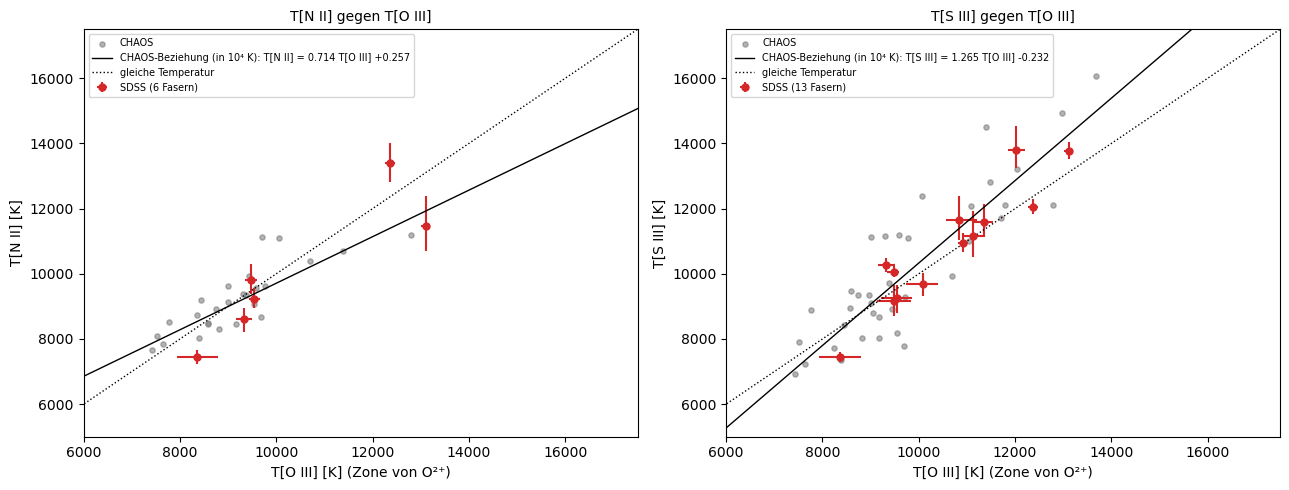

In [12]:
# Temperatur-Temperatur-Beziehungen von CHAOS (Croxall et al. 2016, Gl. 5 und 7; T in 10⁴ K)
TT = {"T_N2": (0.714, 0.257), "T_S3": (1.265, -0.232)}
tt = np.linspace(0.5, 1.8, 50)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (kind, (a, b)), col, lab in zip(axes, TT.items(), ["Te([NII])1", "Te([SIII])1"], ["T[N II]", "T[S III]"]):
    ax.scatter(ch_ab["Te([OIII])1"], ch_ab[col], s=14, c="grey", alpha=0.6, label="CHAOS")
    m = L["T_O3"].notna() & L[kind].notna()
    ax.errorbar(L.loc[m, "T_O3"], L.loc[m, kind],
                xerr=[L.loc[m, "T_O3"] - L.loc[m, "T_O3_lo"], L.loc[m, "T_O3_hi"] - L.loc[m, "T_O3"]],
                yerr=[L.loc[m, kind] - L.loc[m, kind + "_lo"], L.loc[m, kind + "_hi"] - L.loc[m, kind]], fmt="o", ms=5, c="tab:red",
                label=f"SDSS ({m.sum()} Fasern)")
    ax.plot(tt * 1e4, (a * tt + b) * 1e4, "k-", lw=1, label=f"CHAOS-Beziehung (in 10⁴ K): {lab} = {a} T[O III] {b:+.3f}")
    ax.plot(tt * 1e4, tt * 1e4, "k:", lw=1, label="gleiche Temperatur")
    d = L.loc[m, kind] - (a * L.loc[m, "T_O3"] / 1e4 + b) * 1e4
    dc = ch_ab[col] - (a * ch_ab["Te([OIII])1"] / 1e4 + b) * 1e4
    print(f"{lab} gegen T[O III]: {m.sum()} Fasern, Abweichung von der CHAOS-Beziehung Median {d.median():+.0f} K, Streuung {d.std():.0f} K; "
          f"CHAOS selbst: Streuung {dc.std():.0f} K ({dc.notna().sum()} Regionen)")
    ax.set_xlim(6000, 17500)
    ax.set_ylim(5000, 17500)
    ax.set_xlabel("T[O III] [K] (Zone von O²⁺)")
    ax.set_ylabel(f"{lab} [K]")
    ax.set_title(f"{lab} gegen T[O III]", fontsize=10)
    ax.legend(fontsize=7, loc="upper left")
fig.tight_layout()
plt.show()

* Das **linke Bild:** T[N II] gegen T[O III] in den 6 Fasern mit beiden Thermometern, grau die CHAOS-Regionen. Die CHAOS-Beziehung (schwarz) ist flacher als die Linie gleicher Temperatur: In heißem, metallarmem Gas ist die O⁺-Zone kälter als die O²⁺-Zone, in kühlem wärmer. Die SDSS-Punkte weichen im Median um −309 K von der Beziehung ab, mit 1100 K Streuung; bei CHAOS selbst sind es 564 K.
* Das **rechte Bild:** T[S III] gegen T[O III] in 13 Fasern: im Median −509 K von der CHAOS-Beziehung, Streuung 656 K, bei CHAOS 1103 K. Die Streuung ist größer als die Fehlerbalken; T[S III] aus SDSS beruht nur auf 9069 (Schritt 6).
* Mit 6 und 13 Fasern lassen sich die Beziehungen nicht selbst bestimmen, nur prüfen: Die SDSS-Werte sind mit ihnen verträglich. Schritt 10 übernimmt deshalb die CHAOS-Beziehungen, wo ein Thermometer fehlt. Die Antwort auf die Vorhersage: In heißem Gas ist T[N II] niedriger als T[O III].

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-9"></a>

##### *9. Stapeln*

Kann man [O III] 4363 sichtbar machen, wo es in keiner einzelnen Faser nachweisbar ist? Vorher vorhersagen: Um welchen Faktor sollte das S/N steigen, wenn man neun gleich gute Fasern mittelt?

Gestapelt werden die inneren Fasern (R/R25 < 0.45) ohne sicheren Einzelnachweis von 4363, in denen das Gas das Sternlicht überstrahlt (EW(Hβ) > 30 Å). Jedes Spektrum wird ins Ruhesystem geschoben, entrötet, durch seinen Hβ-Fluss geteilt und mit einem festen Gewicht pro Spektrum (aus dem Rauschen im Kontinuum) gemittelt. Um gesättigte Linien herum fehlt das betroffene Spektrum ganz (Theorie, Abschnitt 8).

**Hintergrund & Fachbegriffe:**
- **Ruhesystem:** Wellenlängen durch $(1 + z)$ geteilt, so dass dieselbe Linie in allen Spektren an derselben Stelle liegt.
- **Effektive Zahl** $N_\text{eff}$: wie viele gleich gewichtete Spektren den Stapel ebenso gut machen würden.

Stapel aus 9 Fasern mit R/R25 < 0.45 und EW(Hβ) > 30 Å (Median R/R25 = 0.28), einzeln S/N(4363) zwischen -1.0 und 3.5
  effektive Zahl der Fasern (Σw)²/Σw² = 4.3; größter Anteil einer Faser 33%
  Hg        I/Hβ = 0.5096 ± 0.0030  (S/N 169.8)
  OIII4363  I/Hβ = 0.0045 ± 0.0005  (S/N 8.4)
  OIII5007  I/Hβ = 1.4532 ± 0.0060  (S/N 242.5)
  NII5755   I/Hβ = 0.0041 ± 0.0002  (S/N 19.1)
  NII6584   I/Hβ = 0.5541 ± 0.0013  (S/N 430.2)
  SIII6312  I/Hβ = 0.0087 ± 0.0002  (S/N 45.6)
  SIII9069  I/Hβ = 0.2175 ± 0.0009  (S/N 233.4)
  OII7320   I/Hβ = 0.0156 ± 0.0002  (S/N 66.5)
  OII7330   I/Hβ = 0.0133 ± 0.0002  (S/N 62.8)
  Ha        I/Hβ = 2.7941 ± 0.0063  (S/N 445.9)
  Kontrollen: 5007/4959 = 2.86 (Theorie 2.98), Hα/Hβ = 2.79 (Theorie 2.86)
  T_O3: 8136 (+230 / −250) K
  T_N2: 7821 (+129 / −128) K
  T_S3: 8191 (+62 / −68) K


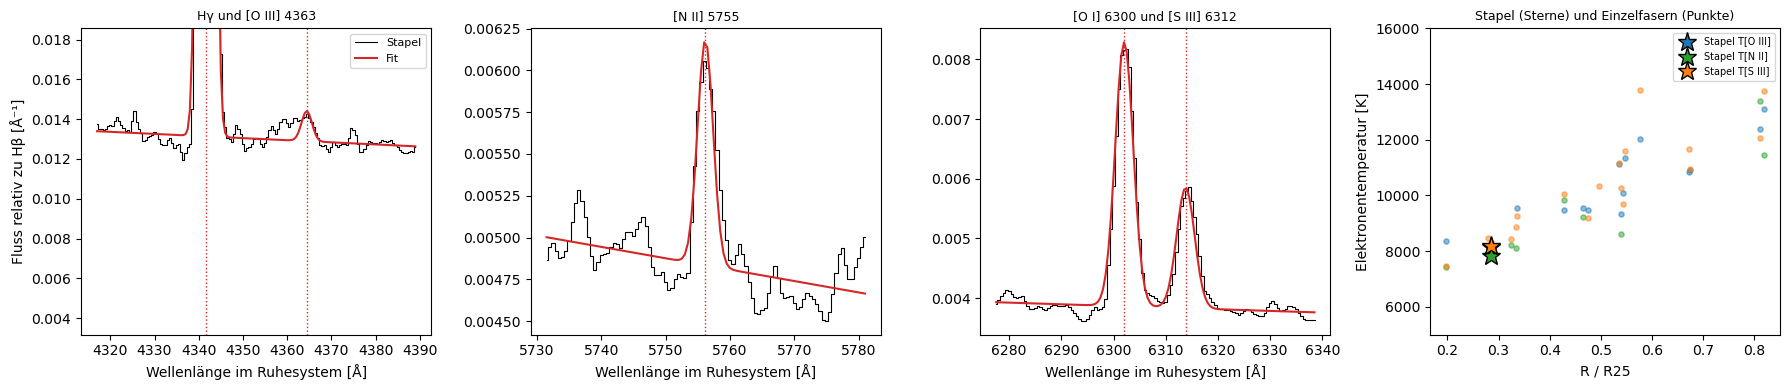

In [13]:
# Innere Fasern ohne sicheren Einzelnachweis von [O III] 4363 im Ruhesystem mitteln (Theorie, Abschnitt 8)
R_STACK, EW_MIN = 0.45, 30.0          # innen; Gas muss das Sternlicht überstrahlen (Äquivalentbreite von Hβ in Å)
cand = L[(L["RR25"] < R_STACK) & (sn("OIII4363") < SN_AUR) & (sn("Hb") > 10) & L["EBV"].notna() & (L["instrument"] == "SDSS")
         & (L["EW_Hb"] > EW_MIN)]
weights = []
grid = np.arange(3800.0, 9180.0, 0.5)
acc, wsum, var = np.zeros_like(grid), np.zeros_like(grid), np.zeros_like(grid)
for _, r in cand.iterrows():
    sp = SPEC[r["i_spec"]]
    w_rest = sp["w"] / (1 + r["z"])
    dered = 10 ** (0.4 * r["EBV"] * (k_ccm(w_rest) - K["Hb"])) / r["Hb"]       # entrötet und relativ zu Hβ
    f = np.interp(grid, w_rest, sp["f"] * dered)
    e = np.interp(grid, w_rest, np.where(sp["iv"] > 0, 1 / np.sqrt(np.where(sp["iv"] > 0, sp["iv"], 1)), np.inf) * dered)
    good = np.isfinite(e)
    for lam in LINES.values():                                  # gesättigte Linie: Spektrum um die ganze Linie herum weglassen
        if (sp["iv"][np.abs(w_rest - lam) < 3] <= 0).any():
            good &= np.abs(grid - lam) > 30
    w0 = 1 / np.median(e[good & (grid > 5100) & (grid < 5600)]) ** 2             # ein festes Gewicht pro Spektrum
    weights.append(w0)
    acc += np.where(good, w0 * f, 0)
    wsum += np.where(good, w0, 0)
    var += np.where(good, w0 ** 2 * e ** 2, 0)
STACK = {"w": grid, "f": 1e3 * acc / wsum, "iv": (wsum / 1e3) ** 2 / var,
         "wdisp": np.interp(grid, SPEC[cand["i_spec"].iloc[0]]["w"] / (1 + cand["z"].iloc[0]), SPEC[cand["i_spec"].iloc[0]]["wdisp"])}
st = {}
for names, mode in GROUPS:
    sig = None
    if mode == "fest":
        sig = cand["width_ratio"].median() * inst_sigma(STACK, LINES[names[0]])
    r = fit_group(STACK, names, 0.0, sig)
    if r:
        for n in r["flux"]:
            st[n], st[n + "_e"] = r["flux"][n] / 1e3, r["err"][n] / 1e3
weights = np.array(weights)
print(f"Stapel aus {len(cand)} Fasern mit R/R25 < {R_STACK} und EW(Hβ) > {EW_MIN:.0f} Å (Median R/R25 = {cand['RR25'].median():.2f}), "
      f"einzeln S/N(4363) zwischen {sn('OIII4363')[cand.index].min():.1f} und {sn('OIII4363')[cand.index].max():.1f}")
print(f"  effektive Zahl der Fasern (Σw)²/Σw² = {weights.sum() ** 2 / (weights ** 2).sum():.1f}; größter Anteil einer Faser "
      f"{weights.max() / weights.sum():.0%}")
for n in ["Hg", "OIII4363", "OIII5007", "NII5755", "NII6584", "SIII6312", "SIII9069", "OII7320", "OII7330", "Ha"]:
    print(f"  {n:9s} I/Hβ = {st[n]:.4f} ± {st[n + '_e']:.4f}  (S/N {st[n] / st[n + '_e']:.1f})")
print(f"  Kontrollen: 5007/4959 = {st['OIII5007'] / st['OIII4959']:.2f} (Theorie {R59:.2f}), Hα/Hβ = {st['Ha']:.2f} (Theorie {HA_HB:.2f})")
sd = {k: st[k] + st[k + "_e"] * rng.standard_normal(4000) for k in ["OIII4363", "OIII5007", "NII5755", "NII6584", "SIII6312", "SIII9069"]}
T_st = {"T_O3": T_from("O3", sd["OIII4363"] / (sd["OIII5007"] * (1 + 1 / R59))),
        "T_N2": T_from("N2", sd["NII5755"] / (sd["NII6584"] * (1 + 1 / r_n2))),
        "T_S3": T_from("S3", sd["SIII6312"] / (sd["SIII9069"] * (1 + r95)))}
for k, v in T_st.items():
    lo, med, hi = np.nanpercentile(v, [16, 50, 84])
    print(f"  {k}: {med:.0f} (+{hi - med:.0f} / −{med - lo:.0f}) K")

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (title, names) in zip(axes[:3], [("Hγ und [O III] 4363", ["Hg", "OIII4363"]), ("[N II] 5755", ["NII5755"]),
                                          ("[O I] 6300 und [S III] 6312", ["OI6300", "SIII6312"])]):
    sig = cand["width_ratio"].median() * inst_sigma(STACK, LINES[names[0]]) if names == ["NII5755"] else None
    r = fit_group(STACK, names, 0.0, sig)
    W, F, model = r["curve"]
    ax.step(W, F / 1e3, where="mid", c="k", lw=0.8, label="Stapel")
    ax.plot(W, model / 1e3, c="tab:red", label="Fit")
    for n in names:
        ax.axvline(LINES[n], c="tab:red", ls=":", lw=1)
    if names[0] == "Hg":
        ax.set_ylim(None, np.median(F / 1e3) + 4 * (st["OIII4363"] / (np.sqrt(2 * np.pi) * 1.3)))
    ax.set_xlabel("Wellenlänge im Ruhesystem [Å]")
    ax.set_title(title, fontsize=9)
axes[0].set_ylabel("Fluss relativ zu Hβ [Å⁻¹]")
axes[0].legend(fontsize=8)
for kind, c in [("T_O3", "tab:blue"), ("T_N2", "tab:green"), ("T_S3", "tab:orange")]:
    mm = L[kind].notna()
    axes[3].scatter(L.loc[mm, "RR25"], L.loc[mm, kind], s=14, c=c, alpha=0.5)
    lo, med, hi = np.nanpercentile(T_st[kind], [16, 50, 84])
    axes[3].errorbar(cand["RR25"].median(), med, yerr=[[med - lo], [hi - med]], fmt="*", ms=14, c=c, mec="k",
                     label=f"Stapel {kind.replace('T_O3', 'T[O III]').replace('T_N2', 'T[N II]').replace('T_S3', 'T[S III]')}")
axes[3].set_xlabel("R / R25")
axes[3].set_ylabel("Elektronentemperatur [K]")
axes[3].set_ylim(5000, 16000)
axes[3].set_title("Stapel (Sterne) und Einzelfasern (Punkte)", fontsize=9)
axes[3].legend(fontsize=7)
fig.tight_layout()
plt.show()

* Die **Ausgabe:** 9 innere Fasern (R/R25 < 0.45, Median 0.28) mit EW(Hβ) > 30 Å, einzeln mit S/N(4363) zwischen −1.0 und 3.5. Im Stapel erreicht [O III] 4363 S/N 8.4, [N II] 5755 S/N 19 und [S III] 6312 S/N 46. Die effektive Zahl der Fasern ist aber nur 4.3, eine Faser trägt 33 % des Gewichts: Die Gewichtung nach dem Rauschen bevorzugt helle Regionen. Erwartet wäre bei neun gleich guten Fasern ein Faktor 3 im S/N, hier sind es eher $\sqrt{4.3} \approx 2$.
* Die **ersten drei Bilder:** [N II] 5755 und [S III] 6312 sind im Stapel klare Linien. Bei 4363 ist die Erhebung breiter als die Fitkurve und reicht nach blau über die erwartete Lage hinaus; vermutlich steckt dort [Fe II] 4359, eine bekannte Verunreinigung in metallreichen Stapeln (Curti et al. 2017). T[O III] ist darum eher eine obere Grenze. Die Kontrolle 5007/4959 = 2.86 statt 2.98 kommt von der hellsten Faser, die selbst 2.86 hat; vermutlich ist ihr 5007 knapp unter der Sättigung nicht mehr linear.
* Das **rechte Bild:** Die Temperaturen des Stapels (Sterne) passen zusammen: T[O III] = 8136 (+230 / −250) K, T[N II] = 7821 ± 129 K, T[S III] = 8191 (+62 / −68) K bei R/R25 ≈ 0.3. Sie liegen etwa 500 K unter der Geraden aus Schritt 7, innerhalb ihrer inneren Streuung von 700 K, und zeigen, dass das Gas innen um 8000 K kühl ist.

[↑ Zurück zur Landkarte](#landkarte)

#### **Modell und Fit**

<a id="exp-10"></a>

##### *10. Von der Temperatur zur Häufigkeit*

Wie wird aus Temperatur und Linienstärke eine Häufigkeit, und wie stark hängt sie an der Temperatur? Vorher vorhersagen: Wird O/H größer oder kleiner, wenn die Temperatur zu hoch geschätzt ist?

Für jede Ziehung aus Schritt 7 bekommen die O²⁺- und die O⁺-Zone ihre Temperatur (gemessen oder über die Beziehungen aus Theorie, Abschnitt 5). O²⁺ folgt aus [O III] 4959 + 5007, O⁺ aus [O II] 3726 + 3729 oder 7320 + 7330, beide relativ zu Hβ (Theorie, Abschnitt 6). Prüfung an CHAOS: Geben 7320/7330 und 3727 dasselbe O⁺?

**Hintergrund & Fachbegriffe:**
- **Emissivität pro Ion:** wie viel Energie pro Sekunde, pro Ion und pro Elektron in einer Linie abgestrahlt wird.
- **Ionisationsgrad:** der Anteil von O²⁺ am gesamten Sauerstoff.

Direkte Sauerstoffhäufigkeit in 19 Fasern; Temperatur aus {'[O III]': 14, '[N II]': 3, '[S III]': 2}, O⁺ aus {'7320/7330': 19}
12 + log(O/H) von 8.04 bis 8.65, Fehler im Median ±0.065 dex; O²⁺-Anteil von 17% bis 77%
  T = 8000 K, +500 K: O²⁺ aus 5007       -0.104 dex
  T = 8000 K, +500 K: O⁺ aus 3727        -0.132 dex
  T = 8000 K, +500 K: O⁺ aus 7320/7330   -0.193 dex
  T = 12000 K, +500 K: O²⁺ aus 5007       -0.055 dex
  T = 12000 K, +500 K: O⁺ aus 3727        -0.067 dex
  T = 12000 K, +500 K: O⁺ aus 7320/7330   -0.094 dex
CHAOS-Regionen: log O⁺(7320/7330) − log O⁺(3727) = -0.008 im Median, Streuung 0.097 (67 Regionen)


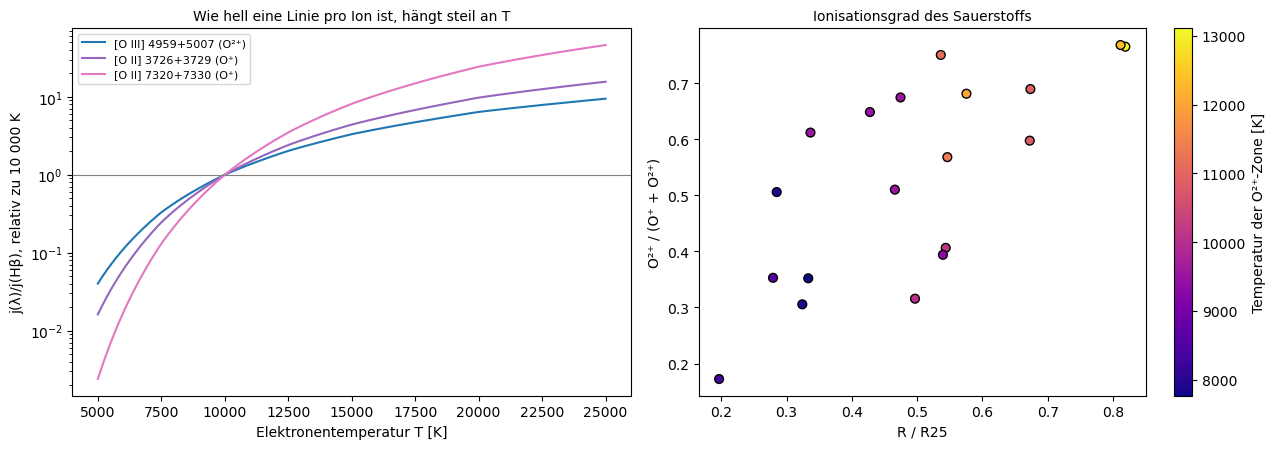

In [14]:
# Emissivitäten relativ zu Hβ als Tabellen (Theorie, Abschnitt 6)
EMIS = {"O3": np.array([O3.line(T, N_E, LINES["OIII4959"]) + O3.line(T, N_E, LINES["OIII5007"]) for T in TG]),
        "O2b": np.array([O2.line(T, N_E, LINES["OII3726"]) + O2.line(T, N_E, LINES["OII3729"]) for T in TG]),
        "O2r": np.array([O2.line(T, N_E, LINES["OII7320"], 2) + O2.line(T, N_E, LINES["OII7330"], 2) for T in TG]),
        "Hb": j_H(TG)}
def ionic(I_rel, key, T):
    # n(Ion)/n(H⁺) = I(λ)/I(Hβ) · j(Hβ)/j(λ)
    return I_rel * np.interp(T, TG, EMIS["Hb"] / EMIS[key], left=np.nan, right=np.nan)

def zones(t):
    # Temperaturen der Zonen von O²⁺ (hoch) und O⁺ (niedrig); fehlende über die CHAOS-Beziehungen (Theorie, Abschnitt 5)
    nan = np.full(len(t["EBV"]), np.nan)
    TO3, TN2, TS3 = t.get("T_O3", nan), t.get("T_N2", nan), t.get("T_S3", nan)
    high = np.where(np.isfinite(TO3), TO3, np.where(np.isfinite(TN2), (TN2 / 1e4 - 0.257) / 0.714 * 1e4,
                                                    (TS3 / 1e4 + 0.232) / 1.265 * 1e4))
    low = np.where(np.isfinite(TN2), TN2, np.where(np.isfinite(TO3), (0.714 * TO3 / 1e4 + 0.257) * 1e4,
                                                   ((TS3 / 1e4 + 0.232) / 1.265 * 0.714 + 0.257) * 1e4))
    src = next((k for k, v in [("[O III]", TO3), ("[N II]", TN2), ("[S III]", TS3)] if np.isfinite(v).mean() > 0.9), "-")
    return high, low, src

for col in ["OH", "OH_lo", "OH_hi", "Opp_frac", "T_high", "T_low"]:
    L[col] = np.nan
L["T_src"], L["O_src"] = "-", "-"
for j, t in DRAWS.items():
    high, low, src = zones(t)
    if src == "-":
        continue
    opp = ionic(t["I5007"] * (1 + 1 / R59), "O3", high)
    if "I3727" in t:
        op, osrc = ionic(t["I3727"], "O2b", low), "3727"
    elif "I7325" in t:
        op, osrc = ionic(t["I7325"], "O2r", low), "7320/7330"
    else:
        continue
    oh = 12 + np.log10(op + opp)
    if np.isfinite(oh).mean() < 0.9:
        continue
    L.loc[j, ["OH_lo", "OH", "OH_hi"]] = np.nanpercentile(oh, [16, 50, 84])
    L.loc[j, ["Opp_frac", "T_high", "T_low"]] = np.nanmedian(opp / (op + opp)), np.nanmedian(high), np.nanmedian(low)
    L.loc[j, ["T_src", "O_src"]] = src, osrc
D = L[L["OH"].notna()].copy()
D["OH_e"] = (D["OH_hi"] - D["OH_lo"]) / 2
print(f"Direkte Sauerstoffhäufigkeit in {len(D)} Fasern; Temperatur aus {D['T_src'].value_counts().to_dict()}, "
      f"O⁺ aus {D['O_src'].value_counts().to_dict()}")
print(f"12 + log(O/H) von {D['OH'].min():.2f} bis {D['OH'].max():.2f}, Fehler im Median ±{D['OH_e'].median():.3f} dex; "
      f"O²⁺-Anteil von {D['Opp_frac'].min():.0%} bis {D['Opp_frac'].max():.0%}")

# Wie stark hängt die Häufigkeit an der Temperatur? +500 K bei 8000 und 12 000 K
for T0 in (8000, 12000):
    for key, lab in [("O3", "O²⁺ aus 5007"), ("O2b", "O⁺ aus 3727"), ("O2r", "O⁺ aus 7320/7330")]:
        d = np.log10(ionic(1.0, key, T0 + 500) / ionic(1.0, key, T0))
        print(f"  T = {T0} K, +500 K: {lab:18s} {d:+.3f} dex")
# Prüfung an CHAOS: O⁺ aus 7320/7330 statt aus 3727, mit der CHAOS-Temperatur der Zone niedriger Ionisation
Tl = ch_ab["Te([NII])2"].reindex(CH.index)
dop = np.log10(ionic(CH["[OII]7320"] + CH["[OII]7330"], "O2r", Tl) / ionic(CH["[OII]3726"] + CH["[OII]3729"], "O2b", Tl)).dropna()
print(f"CHAOS-Regionen: log O⁺(7320/7330) − log O⁺(3727) = {dop.median():+.3f} im Median, Streuung {dop.std():.3f} ({len(dop)} Regionen)")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for key, lab, c in [("O3", "[O III] 4959+5007 (O²⁺)", "tab:blue"), ("O2b", "[O II] 3726+3729 (O⁺)", "tab:purple"),
                    ("O2r", "[O II] 7320+7330 (O⁺)", "tab:pink")]:
    e = EMIS[key] / EMIS["Hb"]
    axes[0].semilogy(TG, e / e[i10], c=c, label=lab)
axes[0].axhline(1, c="grey", lw=0.8)
axes[0].set_xlabel("Elektronentemperatur T [K]")
axes[0].set_ylabel("j(λ)/j(Hβ), relativ zu 10 000 K")
axes[0].set_title("Wie hell eine Linie pro Ion ist, hängt steil an T", fontsize=10)
axes[0].legend(fontsize=8)
sc = axes[1].scatter(D["RR25"], D["Opp_frac"], c=D["T_high"], cmap="plasma", s=40, edgecolor="k")
fig.colorbar(sc, ax=axes[1], label="Temperatur der O²⁺-Zone [K]")
axes[1].set_xlabel("R / R25")
axes[1].set_ylabel("O²⁺ / (O⁺ + O²⁺)")
axes[1].set_title("Ionisationsgrad des Sauerstoffs", fontsize=10)
fig.tight_layout()
plt.show()

* Das **linke Bild:** Wie hell eine Linie pro Ion relativ zu Hβ ist, als Funktion der Temperatur (1 bei 10 000 K). Zwischen 5000 und 10 000 K steigt [O III] 4959 + 5007 um den Faktor 25, [O II] 3726 + 3729 um 60 und [O II] 7320 + 7330 um 400. Die Ausgabe in Zahlen: 500 K mehr senken bei 8000 K O²⁺/H⁺ um 0.10 dex, O⁺ aus 3727 um 0.13 dex und O⁺ aus 7320/7330 um 0.19 dex; bei 12 000 K etwa halb so viel. Die Antwort auf die Vorhersage: Eine zu hohe Temperatur ergibt eine zu kleine Häufigkeit.
* Die **Ausgabe:** Direkte Häufigkeiten in 19 Fasern, 12 + log(O/H) von 8.04 bis 8.65 mit ±0.065 dex Fehler im Median. Die Temperatur der O²⁺-Zone kommt in 14 Fasern aus [O III], in 3 aus [N II] und in 2 aus [S III]. O⁺ kommt immer aus 7320/7330, weil keine BOSS-Faser eine Temperatur hat. Auf den CHAOS-Daten ergeben 7320/7330 und 3727 dasselbe O⁺: im Median −0.008 dex, Streuung 0.10 dex in 67 Regionen.
* Das **rechte Bild:** Der Anteil von O²⁺ steigt von 17 % innen auf 77 % außen, und mit ihm die Temperatur (Farbe). Außen ist das Gas metallärmer; vermutlich sind dort auch die ionisierenden Sterne heißer und ionisieren mehr Sauerstoff zweifach.

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-11"></a>

##### *11. Der direkte Metallizitätsgradient*

Wie stark fällt die direkt gemessene Sauerstoffhäufigkeit nach außen ab? Vorher vorhersagen: Liegt die Häufigkeit im Zentrum über oder unter der der Sonne (8.69)?

Durch die 19 Häufigkeiten wird eine Gerade gegen R/R25 gelegt, gewichtet mit Messfehler und innerer Streuung, so dass $\chi^2$ pro Freiheitsgrad 1 ist.

**Hintergrund & Fachbegriffe:**
- **Metallizitätsgradient:** die Änderung von 12 + log(O/H) mit dem Abstand vom Zentrum, in dex pro R25 oder dex pro kpc. Scheibengalaxien wachsen von innen nach außen; innen haben mehr Sterngenerationen Sauerstoff erbrütet.
- **Residuum:** Abstand eines Punktes von der Geraden.

12 + log(O/H) = 8.717 ± 0.087 -0.742 ± 0.155 · R/R25   (19 Fasern)
  pro kpc: -0.0239 ± 0.0050 dex/kpc (R25 = 31.0 kpc); bei R25: 7.98
  Streuung um die Gerade 0.118 dex, innere Streuung 0.091 dex, Messfehler im Median 0.065 dex
  zum Vergleich die Sonne: 8.69 (Asplund et al. 2009); Abfall von der Mitte bis R25: 0.74 dex = Faktor 5.5


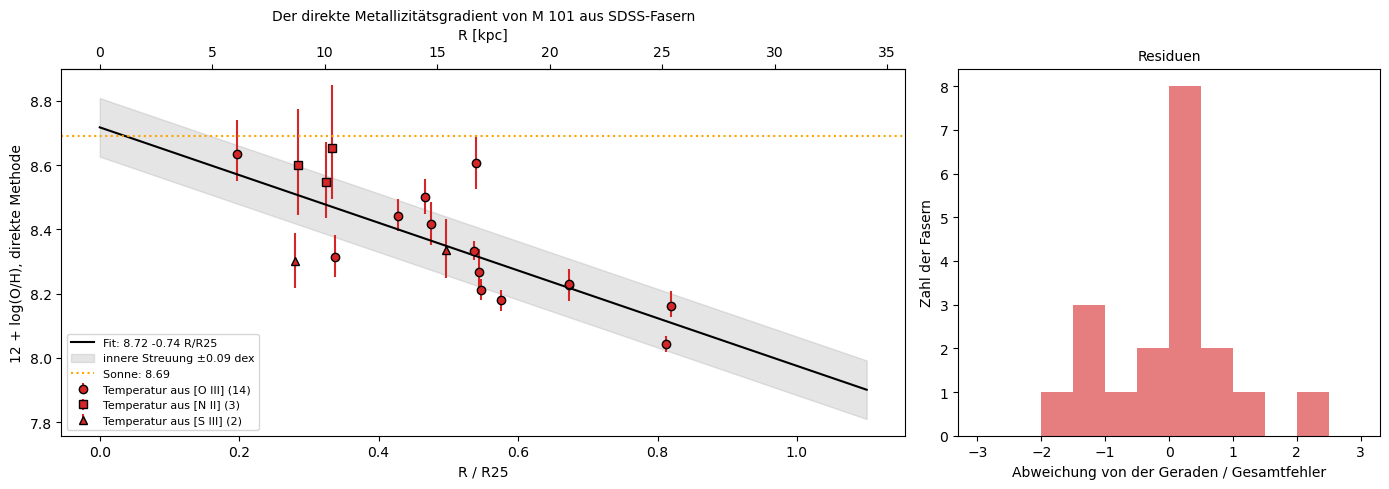

In [15]:
p_own, dp_own, sint_own = fit_gradient(D["RR25"], D["OH"], D["OH_e"])
res = D["OH"] - np.polyval(p_own, D["RR25"])
print(f"12 + log(O/H) = {p_own[1]:.3f} ± {dp_own[1]:.3f} {p_own[0]:+.3f} ± {dp_own[0]:.3f} · R/R25   ({len(D)} Fasern)")
print(f"  pro kpc: {p_own[0] / KPC_PER_R25:+.4f} ± {dp_own[0] / KPC_PER_R25:.4f} dex/kpc (R25 = {KPC_PER_R25:.1f} kpc); "
      f"bei R25: {np.polyval(p_own, 1.0):.2f}")
print(f"  Streuung um die Gerade {res.std():.3f} dex, innere Streuung {sint_own:.3f} dex, Messfehler im Median {D['OH_e'].median():.3f} dex")
print(f"  zum Vergleich die Sonne: 8.69 (Asplund et al. 2009); Abfall von der Mitte bis R25: {-p_own[0]:.2f} dex = Faktor {10 ** -p_own[0]:.1f}")

rr = np.linspace(0, 1.1, 50)
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [2, 1]})
for src, mk in [("[O III]", "o"), ("[N II]", "s"), ("[S III]", "^")]:
    m = D["T_src"] == src
    if m.any():
        axes[0].errorbar(D.loc[m, "RR25"], D.loc[m, "OH"], yerr=[D.loc[m, "OH"] - D.loc[m, "OH_lo"], D.loc[m, "OH_hi"] - D.loc[m, "OH"]],
                         fmt=mk, ms=6, c="tab:red", mec="k", label=f"Temperatur aus {src} ({m.sum()})")
axes[0].plot(rr, np.polyval(p_own, rr), "k-", label=f"Fit: {p_own[1]:.2f} {p_own[0]:+.2f} R/R25")
axes[0].fill_between(rr, np.polyval(p_own, rr) - sint_own, np.polyval(p_own, rr) + sint_own, color="grey", alpha=0.2,
                     label=f"innere Streuung ±{sint_own:.2f} dex")
axes[0].axhline(8.69, c="orange", ls=":", label="Sonne: 8.69")
axes[0].set_xlabel("R / R25")
axes[0].set_ylabel("12 + log(O/H), direkte Methode")
axes[0].set_title("Der direkte Metallizitätsgradient von M 101 aus SDSS-Fasern", fontsize=10)
axes[0].legend(fontsize=8)
sec = axes[0].secondary_xaxis("top", functions=(lambda x: x * KPC_PER_R25, lambda x: x / KPC_PER_R25))
sec.set_xlabel("R [kpc]")
axes[1].hist(res / np.sqrt(D["OH_e"] ** 2 + sint_own ** 2), bins=np.arange(-3, 3.25, 0.5), color="tab:red", alpha=0.6)
axes[1].set_xlabel("Abweichung von der Geraden / Gesamtfehler")
axes[1].set_ylabel("Zahl der Fasern")
axes[1].set_title("Residuen", fontsize=10)
fig.tight_layout()
plt.show()

* Das **linke Bild:** Die direkte Häufigkeit fällt nach außen: $12 + \log(\text{O/H}) = 8.717 \pm 0.087 - (0.742 \pm 0.155)\,R/R_{25}$, also $-0.024 \pm 0.005$ dex/kpc. Im Zentrum ist sie etwa so hoch wie in der Sonne (8.69), bei R25 nur 7.98; von innen bis R25 sinkt sie um 0.74 dex, den Faktor 5.5. Die Antwort auf die Vorhersage: im Zentrum etwa gleich der Sonne.
* Die Punkte streuen um 0.118 dex um die Gerade; die Messfehler (Median 0.065 dex) erklären nur einen Teil davon, die innere Streuung beträgt 0.091 dex (grau). Das sind echte Unterschiede zwischen Regionen oder Fehler, die die Monte-Carlo-Rechnung nicht kennt, etwa die Wahl der Temperatur der O⁺-Zone (Variation 3). Die drei Fasern mit Temperatur nur aus [N II] (Quadrate) liegen innen alle über der Geraden.
* Das **rechte Bild:** Die Residuen, geteilt durch den Gesamtfehler aus Messfehler und innerer Streuung, liegen zwischen −2 und +2.5; keine Faser fällt aus dem Rahmen.

[↑ Zurück zur Landkarte](#landkarte)

#### **Eigene Messung gegen den Katalog**

<a id="exp-12"></a>

##### *12. Faser für Faser gegen CHAOS*

Messen SDSS-Faser und CHAOS-Spalt dasselbe, wenn sie auf dieselbe Region zeigen? Vorher vorhersagen: Wo ist die Streuung zwischen beiden größer, bei Hα/Hβ oder bei [S II] 6717/Hβ?

Für die 14 Paare aus Schritt 1 werden entrötete Linienstärken, Temperaturen und Häufigkeiten verglichen.

**Hintergrund & Fachbegriffe:**
- **Blende (Apertur):** der Himmelsausschnitt, aus dem ein Spektrum stammt; Faser rund mit 3″, CHAOS ein Abschnitt eines 1″ breiten Spalts.

14 SDSS-Fasern liegen innerhalb von 3″ einer CHAOS-Region; Abstand Faser–Spalt im Median 2.1″
Linie          Paare  log(eigen/CHAOS)  Streuung
Hα                11            +0.007     0.030
[O III] 5007      11            -0.036     0.115
[N II] 6584       13            -0.003     0.167
[S II] 6717       13            -0.024     0.212
[S III] 9069      12            +0.010     0.149
[O II] 7320       11            -0.020     0.145
[S III] 6312      11            +0.011     0.122
[O III] 4363       8            +0.012     0.161
[N II] 5755        5            -0.016     0.055
T[O III]: 6 Paare, eigen minus CHAOS: +92, -62, +150, +23, +637, +92 K
T[N II]: 5 Paare, eigen minus CHAOS: -712, +743, -275, -775, -816 K
T[S III]: 8 Paare, eigen minus CHAOS: +1878, -568, +1725, -882, -713, -469, +143, +1130 K
O/H: 9 Paare, eigen minus CHAOS: +0.11, -0.01, +0.03, -0.03, +0.18, -0.03, +0.18, -0.02, -0.23; Median -0.014, Streuung 0.119 dex


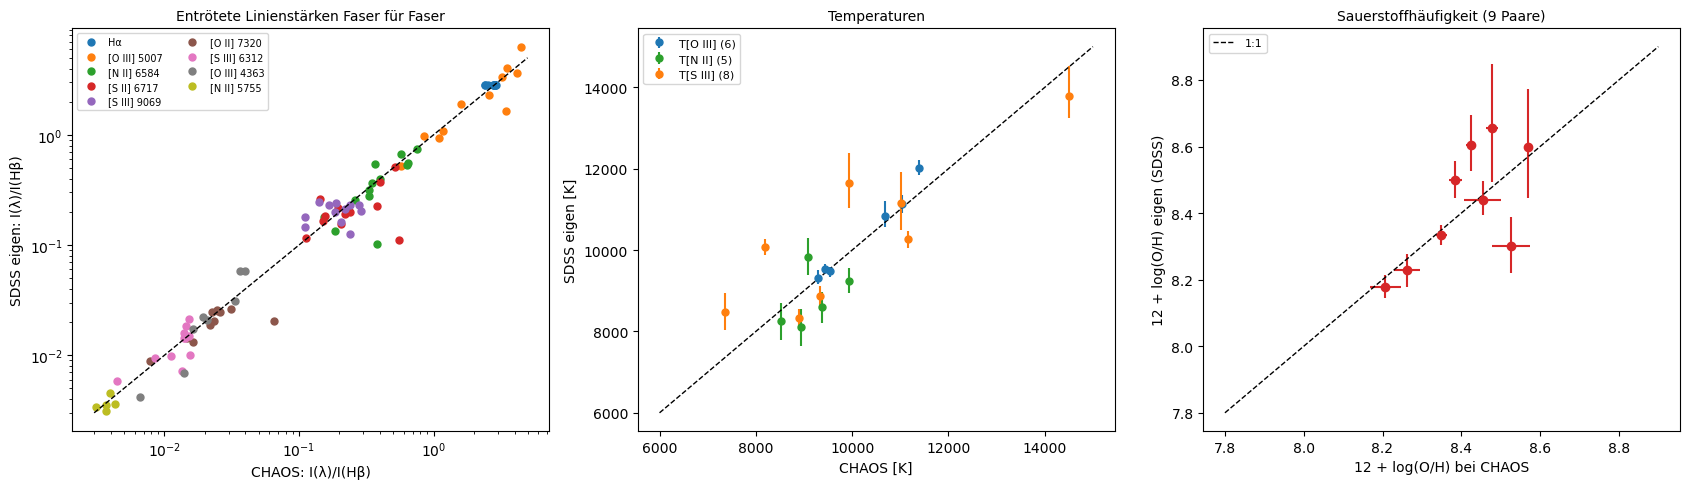

In [16]:
P = L[L["chaos"].notna()].copy()
pairs = {"Hα": ("Ha", "Halpha6563"), "[O III] 5007": ("OIII5007", "[OIII]5007"), "[N II] 6584": ("NII6584", "[NII]6583"),
         "[S II] 6717": ("SII6717", "[SII]6716"), "[S III] 9069": ("SIII9069", "[SIII]9069"), "[O II] 7320": ("OII7320", "[OII]7320"),
         "[S III] 6312": ("SIII6312", "[SIII]6312"), "[O III] 4363": ("OIII4363", "[OIII]4363"), "[N II] 5755": ("NII5755", "[NII]5755")}
own_I = lambda n, col: (P[col] / P["Hb"] * 10 ** (0.4 * P["EBV"] * (K[n] - K["Hb"]))).where(sn(col)[P.index] > SN_STRONG)
print(f"{len(P)} SDSS-Fasern liegen innerhalb von 3″ einer CHAOS-Region; Abstand Faser–Spalt im Median "
      f"{np.median(SkyCoord(P['ra'].values * u.deg, P['dec'].values * u.deg).separation(ch_c[[ch_pos.index[ch_pos['HIIid'] == c][0] for c in P['chaos']]]).arcsec):.1f}″")
print(f"{'Linie':14s} {'Paare':>5s} {'log(eigen/CHAOS)':>17s} {'Streuung':>9s}")
cmp_rows = []
for lab, (n, chcol) in pairs.items():
    a, b = own_I(n, n), CH.loc[P["chaos"], chcol].values
    d = np.log10(a.values / b)
    ok = np.isfinite(d)
    cmp_rows.append((lab, a.values[ok], b[ok]))
    print(f"{lab:14s} {ok.sum():5d} {np.median(d[ok]):+17.3f} {np.std(d[ok]):9.3f}")
chP = ch_ab.reindex(P["chaos"].values)
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
cols = plt.cm.tab10(np.arange(len(cmp_rows)))
for (lab, a, b), c in zip(cmp_rows, cols):
    axes[0].loglog(b, a, "o", ms=5, c=c, label=lab)
axes[0].plot([3e-3, 5], [3e-3, 5], "k--", lw=1)
axes[0].set_xlabel("CHAOS: I(λ)/I(Hβ)")
axes[0].set_ylabel("SDSS eigen: I(λ)/I(Hβ)")
axes[0].set_title("Entrötete Linienstärken Faser für Faser", fontsize=10)
axes[0].legend(fontsize=7, ncol=2)
for kind, c, lab in [("T_O3", "tab:blue", "T[O III]"), ("T_N2", "tab:green", "T[N II]"), ("T_S3", "tab:orange", "T[S III]")]:
    x, y = chP[CHT[kind[2:]]].values, P[kind].values
    ok = np.isfinite(x) & np.isfinite(y)
    axes[1].errorbar(x[ok], y[ok], yerr=[(P[kind] - P[kind + "_lo"]).values[ok], (P[kind + "_hi"] - P[kind]).values[ok]],
                     fmt="o", ms=5, c=c, label=f"{lab} ({ok.sum()})")
    if ok.any():
        print(f"{lab}: {ok.sum()} Paare, eigen minus CHAOS: " + ", ".join(f"{v:+.0f}" for v in (y - x)[ok]) + " K")
axes[1].plot([6000, 15000], [6000, 15000], "k--", lw=1)
axes[1].set_xlabel("CHAOS [K]")
axes[1].set_ylabel("SDSS eigen [K]")
axes[1].set_title("Temperaturen", fontsize=10)
axes[1].legend(fontsize=8)
x, y = chP["12+log(O/H)"].values, P["OH"].values
ok = np.isfinite(x) & np.isfinite(y)
axes[2].errorbar(x[ok], y[ok], xerr=chP["e_12+log(O/H)"].values[ok],
                 yerr=[(P["OH"] - P["OH_lo"]).values[ok], (P["OH_hi"] - P["OH"]).values[ok]], fmt="o", ms=6, c="tab:red")
axes[2].plot([7.8, 8.9], [7.8, 8.9], "k--", lw=1, label="1:1")
axes[2].set_xlabel("12 + log(O/H) bei CHAOS")
axes[2].set_ylabel("12 + log(O/H) eigen (SDSS)")
axes[2].set_title(f"Sauerstoffhäufigkeit ({ok.sum()} Paare)", fontsize=10)
axes[2].legend(fontsize=8)
print(f"O/H: {ok.sum()} Paare, eigen minus CHAOS: " + ", ".join(f"{v:+.2f}" for v in (y - x)[ok]) +
      f"; Median {np.median((y - x)[ok]):+.3f}, Streuung {np.std((y - x)[ok]):.3f} dex")
fig.tight_layout()
plt.show()

* Das **linke Bild:** Für die 14 Paare (Faser und Spalt im Median 2.0″ auseinander) liegen die entröteten Linienstärken über drei Größenordnungen auf der 1:1-Linie; im Median weichen alle Linien um höchstens 0.04 dex ab. Hα streut nur um 0.03 dex, denn nach der Entrötung legt die Atomphysik Hα/Hβ fest. [N II] 6584, [S II] 6717 und [S III] 9069 streuen um 0.15 bis 0.21 dex: Die runde Faser (3″) und der schmale Spalt (1″) sehen verschiedene Teile einer Region, und die Ionisation ändert sich innerhalb einer Region. Die Antwort auf die Vorhersage: Die Streuung ist bei [S II] viel größer als bei Hα.
* Das **mittlere Bild:** T[O III] stimmt in 5 von 6 Paaren auf 150 K (das sechste +637 K). T[N II] liegt in 4 von 5 Paaren 275 bis 816 K tiefer als bei CHAOS, obwohl [N II] 5755 selbst im Median auf 0.02 dex übereinstimmt; die Unterschiede kommen über [N II] 6584 aus den verschiedenen Blenden. T[S III] streut um bis zu 1900 K, wie nach Schritt 6 zu erwarten, weil SDSS nur 9069 hat.
* Das **rechte Bild:** O/H stimmt in 9 Paaren im Median auf −0.014 dex, mit 0.12 dex Streuung. Das ist etwa die innere Streuung des Gradienten (Schritt 11).

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-13"></a>

##### *13. Der Gradient gegen CHAOS*

Ergibt sich aus 19 SDSS-Fasern derselbe Gradient wie aus 77 CHAOS-Regionen? Vorher vorhersagen: Wie viel größer sollte der Fehler der Steigung bei 19 statt 77 Regionen sein, wenn sonst alles gleich wäre?

Dieselbe Fitfunktion läuft über die CHAOS-Tabelle; daneben steht die Gerade aus dem Paper (Croxall et al. 2016, Gl. 10).

**Hintergrund & Fachbegriffe:**
- **σ-Abstand:** Unterschied zweier Werte geteilt durch ihren gemeinsamen Fehler $\sqrt{\sigma_1^2 + \sigma_2^2}$.

CHAOS, eigener Fit an die Tabelle (77 Regionen): 8.710 ± 0.023 -0.810 ± 0.046 R/R25, innere Streuung 0.081 dex
CHAOS im Paper: 8.716 ± 0.023 -0.832 ± 0.044 R/R25, innere Streuung 0.074 dex
SDSS eigen (19 Fasern): 8.717 ± 0.087 -0.742 ± 0.155 R/R25, innere Streuung 0.091 dex
  Achsenabschnitt: Unterschied +0.001 = +0.0 σ
  Steigung: Unterschied +0.090 = +0.6 σ
  bei R/R25 = 0.2: SDSS 8.57, CHAOS 8.55
  bei R/R25 = 0.5: SDSS 8.35, CHAOS 8.30
  bei R/R25 = 0.8: SDSS 8.12, CHAOS 8.05


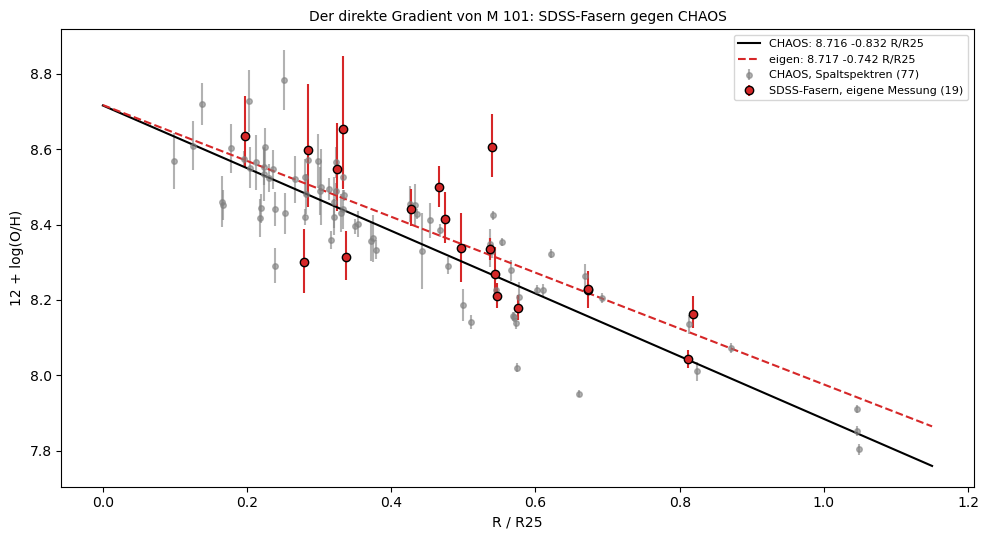

In [17]:
chg = pd.DataFrame({"R": ch_pos.set_index("HIIid")["RgR25"], "OH": ch_ab["12+log(O/H)"], "e": ch_ab["e_12+log(O/H)"]}).dropna()
p_ch, dp_ch, sint_ch = fit_gradient(chg["R"], chg["OH"], chg["e"])
PAPER = (8.716, 0.023, -0.832, 0.044)                    # Croxall et al. (2016), Gl. 10
print(f"CHAOS, eigener Fit an die Tabelle ({len(chg)} Regionen): {p_ch[1]:.3f} ± {dp_ch[1]:.3f} {p_ch[0]:+.3f} ± {dp_ch[0]:.3f} R/R25, "
      f"innere Streuung {sint_ch:.3f} dex")
print(f"CHAOS im Paper: {PAPER[0]} ± {PAPER[1]} {PAPER[2]:+.3f} ± {PAPER[3]} R/R25, innere Streuung 0.074 dex")
print(f"SDSS eigen ({len(D)} Fasern): {p_own[1]:.3f} ± {dp_own[1]:.3f} {p_own[0]:+.3f} ± {dp_own[0]:.3f} R/R25, innere Streuung {sint_own:.3f} dex")
for name, (v, dv, pv, pdv) in {"Achsenabschnitt": (p_own[1], dp_own[1], PAPER[0], PAPER[1]),
                               "Steigung": (p_own[0], dp_own[0], PAPER[2], PAPER[3])}.items():
    print(f"  {name}: Unterschied {v - pv:+.3f} = {(v - pv) / np.hypot(dv, pdv):+.1f} σ")
for R0 in (0.2, 0.5, 0.8):
    print(f"  bei R/R25 = {R0}: SDSS {np.polyval(p_own, R0):.2f}, CHAOS {PAPER[0] + PAPER[2] * R0:.2f}")

rr = np.linspace(0, 1.15, 50)
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.errorbar(chg["R"], chg["OH"], yerr=chg["e"], fmt="o", ms=4, c="grey", alpha=0.6, label=f"CHAOS, Spaltspektren ({len(chg)})")
ax.errorbar(D["RR25"], D["OH"], yerr=[D["OH"] - D["OH_lo"], D["OH_hi"] - D["OH"]], fmt="o", ms=6, c="tab:red", mec="k",
            label=f"SDSS-Fasern, eigene Messung ({len(D)})")
ax.plot(rr, PAPER[0] + PAPER[2] * rr, c="k", lw=1.5, label=f"CHAOS: {PAPER[0]} {PAPER[2]:+.3f} R/R25")
ax.plot(rr, np.polyval(p_own, rr), c="tab:red", ls="--", lw=1.5, label=f"eigen: {p_own[1]:.3f} {p_own[0]:+.3f} R/R25")
ax.set_xlabel("R / R25")
ax.set_ylabel("12 + log(O/H)")
ax.set_title("Der direkte Gradient von M 101: SDSS-Fasern gegen CHAOS", fontsize=10)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

* Das **Bild** zeigt CHAOS (grau, 77 Regionen) und die eigene Messung (rot, 19 Fasern) mit beiden Geraden. Der eigene Fit an die CHAOS-Tabelle ergibt 8.710 − 0.810·R/R25, das Paper 8.716 − 0.832·R/R25; der kleine Unterschied liegt an der Gewichtung.
* Aus den SDSS-Fasern: 8.717 ± 0.087 − (0.742 ± 0.155)·R/R25. Der Achsenabschnitt ist gleich (0.0 σ), die Steigung um 0.09 dex/R25 flacher (0.6 σ). Bei R/R25 = 0.2, 0.5 und 0.8 gibt SDSS 8.57, 8.35 und 8.12, CHAOS 8.55, 8.30 und 8.05; der größte Unterschied ist 0.07 dex, außen.
* Der Fehler der Steigung ist 3.5-mal so groß wie bei CHAOS, nicht nur $\sqrt{77/19} \approx 2$-mal wie in der Vorhersage: Die SDSS-Fasern mit Temperatur liegen nur zwischen 0.2 und 0.82 R25, und jede einzelne Häufigkeit ist ungenauer. Die innere Streuung ist mit 0.091 dex fast so klein wie bei CHAOS (0.081 dex im eigenen Fit).

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-14"></a>

##### *14. Starke Linien gegen die direkte Methode*

Welche Eichung aus starken Linien trifft die direkte Methode, und welche nicht? Vorher vorhersagen: Liegen die Häufigkeiten aus Photoionisationsmodellen (MPA-JHU) über oder unter der direkten Methode?

Für alle Fasern mit Sternentstehung (unter der Kauffmann-Linie im BPT-Diagramm) werden die Eichungen aus Theorie, Abschnitt 7 ausgewertet und die MPA-JHU-Werte aus SDSS geholt; verglichen wird Faser für Faser und als Gradient.

**Hintergrund & Fachbegriffe:**
- **Eichung:** eine Formel, die aus Verhältnissen starker Linien O/H schätzt.
- **Kauffmann-Linie:** Grenze im BPT-Diagramm, unter der junge Sterne das Gas ionisieren (Kauffmann et al. 2003).

42 Fasern mit Sternentstehung und allen vier starken Linien; 37 davon mit MPA-JHU-Wert
Eichung                            Paare  minus direkt  Streuung  Gradient [dex/R25]
N2, Pettini & Pagel (2004)            15        -0.115     0.142              -0.527
O3N2, Pettini & Pagel (2004)          15        -0.132     0.154              -0.591
N2, Marino et al. (2013)              15        -0.152     0.140              -0.427
O3N2, Marino et al. (2013)            15        -0.187     0.147              -0.395
MPA-JHU, Tremonti et al. (2004)       15        +0.437     0.137              -1.004
direkt (Schritt 11)                                                           -0.742


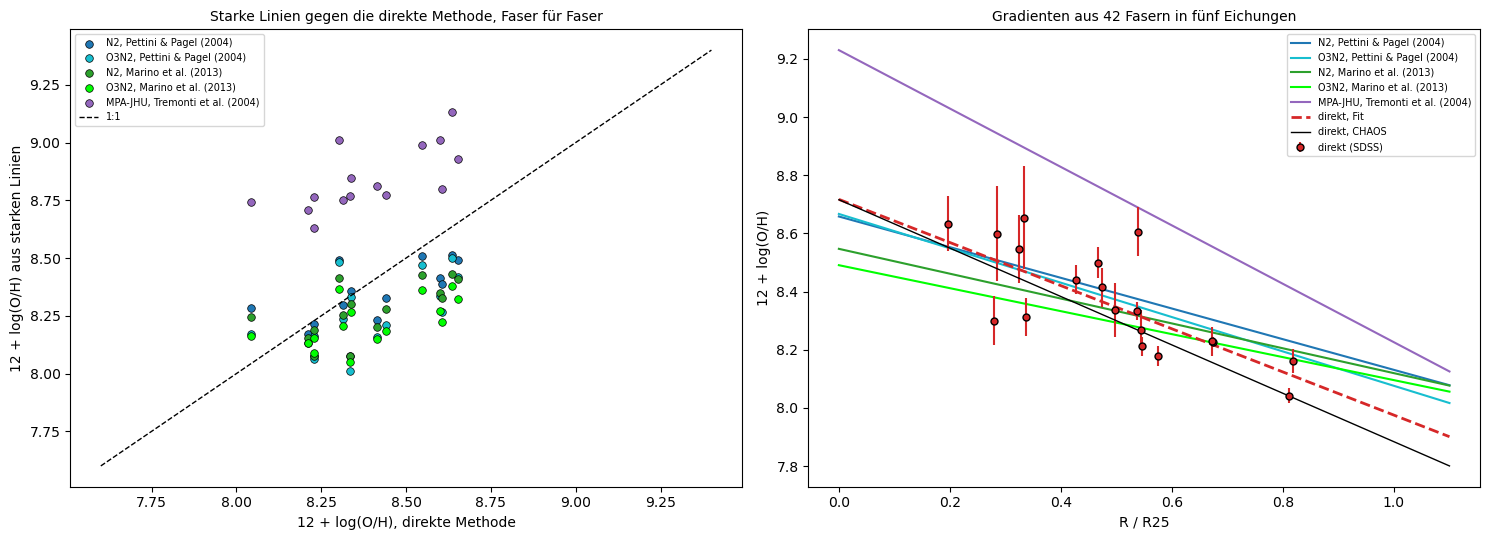

In [18]:
# Häufigkeiten aus starken Linien (Theorie, Abschnitt 7) für alle Fasern mit Sternentstehung
ids = ",".join(L["specObjID"])
mpa = sdss_query(f"SELECT e.specObjID, e.oh_p50 FROM galSpecExtra AS e WHERE e.specObjID IN ({ids})").to_pandas()
mpa["specObjID"] = mpa["specObjID"].astype(str)
L = L.drop(columns=[c for c in ["oh_p50"] if c in L]).merge(mpa, on="specObjID", how="left")
L["oh_p50"] = L["oh_p50"].where(L["oh_p50"] > 0)
L["logN2"] = np.log10(L["NII6584"] / L["Ha"])
L["logO3"] = np.log10(L["O5007"] / L["Hb"])
L["O3N2"] = L["logO3"] - L["logN2"]
sf = ((sn("Ha") > SN_STRONG) & (sn("Hb") > SN_STRONG) & (sn("NII6584") > SN_STRONG) & (L["O5007"] / L["O5007_e"] > SN_STRONG)
      & (L["logN2"] < 0) & (L["logO3"] < 0.61 / (L["logN2"] - 0.05) + 1.30))      # unter der Kauffmann-Linie im BPT-Diagramm
CAL = {"N2, Pettini & Pagel (2004)": 8.90 + 0.57 * L["logN2"], "O3N2, Pettini & Pagel (2004)": 8.73 - 0.32 * L["O3N2"],
       "N2, Marino et al. (2013)": 8.743 + 0.462 * L["logN2"], "O3N2, Marino et al. (2013)": 8.533 - 0.214 * L["O3N2"],
       "MPA-JHU, Tremonti et al. (2004)": L["oh_p50"]}
print(f"{sf.sum()} Fasern mit Sternentstehung und allen vier starken Linien; {L.loc[sf, 'oh_p50'].notna().sum()} davon mit MPA-JHU-Wert")
print(f"{'Eichung':34s} {'Paare':>5s} {'minus direkt':>13s} {'Streuung':>9s} {'Gradient [dex/R25]':>19s}")
p_cal = {}
for name, val in CAL.items():
    d = (val - L["OH"])[L["OH"].notna() & sf]
    m = sf & val.notna()
    p_cal[name] = np.polyfit(L.loc[m, "RR25"], val[m], 1)
    print(f"{name:34s} {d.notna().sum():5d} {d.median():+13.3f} {d.std():9.3f} {p_cal[name][0]:+19.3f}")
print(f"{'direkt (Schritt 11)':34s} {'':5s} {'':>13s} {'':>9s} {p_own[0]:+19.3f}")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
cols = ["tab:blue", "tab:cyan", "tab:green", "lime", "tab:purple"]
for (name, val), c in zip(CAL.items(), cols):
    m = L["OH"].notna() & sf & val.notna()
    axes[0].scatter(L.loc[m, "OH"], val[m], s=30, c=c, edgecolor="k", lw=0.5, label=name)
axes[0].plot([7.6, 9.4], [7.6, 9.4], "k--", lw=1, label="1:1")
axes[0].set_xlabel("12 + log(O/H), direkte Methode")
axes[0].set_ylabel("12 + log(O/H) aus starken Linien")
axes[0].set_title("Starke Linien gegen die direkte Methode, Faser für Faser", fontsize=10)
axes[0].legend(fontsize=7)
rr = np.linspace(0, 1.1, 50)
for (name, val), c in zip(CAL.items(), cols):
    axes[1].plot(rr, np.polyval(p_cal[name], rr), c=c, lw=1.5, label=name)
axes[1].errorbar(D["RR25"], D["OH"], yerr=D["OH_e"], fmt="o", ms=5, c="tab:red", mec="k", label="direkt (SDSS)")
axes[1].plot(rr, np.polyval(p_own, rr), c="tab:red", lw=2, ls="--", label="direkt, Fit")
axes[1].plot(rr, PAPER[0] + PAPER[2] * rr, c="k", lw=1, label="direkt, CHAOS")
axes[1].set_xlabel("R / R25")
axes[1].set_ylabel("12 + log(O/H)")
axes[1].set_title(f"Gradienten aus {sf.sum()} Fasern in fünf Eichungen", fontsize=10)
axes[1].legend(fontsize=7)
fig.tight_layout()
plt.show()

* Die **Ausgabe:** 42 Fasern mit Sternentstehung und allen vier starken Linien, 37 davon mit MPA-JHU-Wert; 15 haben auch eine direkte Häufigkeit (bei 4 fehlt N2, weil Hα gesättigt ist). Gegenüber der direkten Methode liegen Pettini & Pagel 0.12 dex (N2) und 0.13 dex (O3N2) zu tief, Marino et al. 0.15 und 0.19 dex zu tief, MPA-JHU 0.44 dex zu hoch; die Streuung ist bei allen etwa 0.14 dex. Die Antwort auf die Vorhersage: Die Modelle liegen darüber.
* Das **linke Bild:** Die empirischen Eichungen drängen die Werte auf 8.0 bis 8.5 zusammen, während die direkte Methode 8.04 bis 8.65 umfasst: Ihre Formeln sind flacher, als die Daten von M 101 verlangen, und N2 sättigt bei hoher Häufigkeit. MPA-JHU liegt durchgehend über der 1:1-Linie.
* Das **rechte Bild:** Die empirischen Gradienten sind mit −0.40 bis −0.59 dex/R25 flacher als der direkte (−0.74) und der von CHAOS (−0.83), MPA-JHU ist steiler (−1.00) und liegt 0.4 bis 0.5 dex höher. Damit löst sich die Frage aus [Emissionslinien von H-II-Regionen](https://github.com/deltorobarba/science/blob/main/astro/galaxies_hiiregions.ipynb) auf: Von den 0.6 dex zwischen MPA-JHU und Pettini & Pagel liegen gut 0.1 dex bei Pettini & Pagel (zu tief) und gut 0.4 dex bei MPA-JHU (zu hoch), gemessen an der Temperatur.

[↑ Zurück zur Landkarte](#landkarte)

#### **Ergebnis**

Beim Lauf vom 2026-11-07 (M 101, 7.4 Mpc, R25 = 31.0 kpc):

- **Daten:** 76 SDSS-Spektren im Kasten um M 101, davon 54 auf Gas der Galaxie (48 vom SDSS-, 6 vom BOSS-Spektrographen) und 22 Vordergrundsterne. CHAOS hat 102 Regionen, 74 mit mindestens einer gemessenen Temperatur und 77 mit O/H. 14 Fasern liegen innerhalb von 3″ einer CHAOS-Region. Die eigenen Abstände R/R25 treffen die von CHAOS auf 0.002.
- **Schwache Linien:** In NGC 5471 ist [O III] 4363 ein Viertel so hoch wie Hγ, [N II] 5755 nur 0.3 %. Mit Lage und Breite aus den starken Linien sind [O III] 4363 in 15 Fasern, [N II] 5755 in 10, [S III] 6312 in 21 und [O II] 7320/7330 in 23 bis 24 Fasern mit S/N > 5 nachgewiesen. 540 Leermessungen streuen um 1.11 statt 1 (die Pipeline-Fehler sind etwa 10 % zu klein); keine erreicht S/N 5.
- **Sättigung und Staub:** In 3 Fasern ist [O III] 5007 gesättigt und wird durch 2.98 × 4959 ersetzt (gemessen 3.00 ± 0.11), in 4 Hα; dort kommt der Staub aus Hγ/Hβ. E(B−V) ist im Median 0.21 mag; dann schwächt der Staub 4363 um 12 % mehr als 5007.
- **Dichte:** [S II] 6717/6731 = 1.38 im Median, $n_e \approx 60$ cm⁻³. Bis 1000 cm⁻³ ändern sich die Thermometer um weniger als 1 %.
- **Atom:** Das eigene Fünf-Niveau-Atom trifft die CHAOS-Temperaturen aus deren eigenen Linien auf −19 K ([O III], Streuung 22 K), −102 K ([N II]) und +6 K ([S III]). Mit nur [S III] 9069 und 9532 aus der Theorie wächst die Streuung auf 577 K (tellurische Absorption).
- **Temperaturen:** T[O III] in 14 Fasern von 8356 bis 13 109 K (Fehler ±190 K im Median), T[N II] in 9, T[S III] in 18. T[O III] steigt um 7100 ± 1200 K pro R25. Die Paare von Thermometern sind mit den CHAOS-Beziehungen verträglich.
- **Stapel:** Neun innere Fasern ohne Einzelnachweis ($N_\text{eff} = 4.3$) ergeben [O III] 4363 mit S/N 8.4 und T[O III] = 8140 K, T[N II] = 7820 K, T[S III] = 8190 K bei R/R25 ≈ 0.3. Die Erhebung bei 4363 reicht nach blau, vermutlich durch [Fe II] 4359.
- **Häufigkeiten:** Direkte O/H in 19 Fasern, von 8.04 bis 8.65 (±0.065 dex). 500 K mehr senken O²⁺ bei 8000 K um 0.10 dex und O⁺ aus 7320/7330 um 0.19 dex. Auf den CHAOS-Daten ergeben 7320/7330 und 3727 dasselbe O⁺ (−0.008 ± 0.10 dex).
- **Gradient:** $12 + \log(\text{O/H}) = 8.717 \pm 0.087 - (0.742 \pm 0.155)\,R/R_{25}$, also $-0.024 \pm 0.005$ dex/kpc, mit 0.09 dex innerer Streuung. CHAOS: $8.716 \pm 0.023 - (0.832 \pm 0.044)\,R/R_{25}$. Achsenabschnitt gleich, Steigung 0.6 σ flacher.
- **Faser gegen Spalt:** In 14 Paaren stimmen die entröteten Linienstärken im Median auf 0.04 dex; T[O III] in 5 von 6 Paaren auf 150 K, O/H in 9 Paaren auf −0.01 ± 0.12 dex.
- **Starke Linien:** Gegenüber der direkten Methode liegen Pettini & Pagel 0.12 (N2) und 0.13 dex (O3N2) zu tief, Marino et al. 0.15 und 0.19 dex zu tief, MPA-JHU 0.44 dex zu hoch. Die empirischen Gradienten sind flacher (−0.40 bis −0.59 dex/R25), MPA-JHU steiler (−1.00).

Deutung: Mit den zufällig auf M 101 gelegten SDSS-Fasern lässt sich die direkte Methode vollständig nachvollziehen. Das Ergebnis trifft das Ergebnis eines eigens dafür gebauten Projekts am 8-m-Teleskop im Achsenabschnitt genau und in der Steigung innerhalb von einem Sigma. Die 0.6 dex zwischen MPA-JHU und Pettini & Pagel aus dem Notebook über H-II-Regionen lösen sich so auf: Gemessen an der Temperatur liegen die empirischen Eichungen etwa 0.1 dex zu tief, die Modelle von MPA-JHU etwa 0.4 dex zu hoch. Offen bleibt, ob die direkte Methode selbst wegen Temperaturschwankungen zu niedrig misst (Theorie, Abschnitt 7).

#### **Variationen**

Jeweils zuerst die Vorhersage notieren, dann den Code ändern und prüfen:

1. **Schwächere Nachweise zulassen:** `SN_AUR = 3.0`. *(Vorhersage: 24 statt 19 Fasern bekommen eine Häufigkeit, aber die Streuung um den Gradienten verdoppelt sich etwa, von 0.12 auf 0.26 dex, mit Ausreißern nach beiden Seiten. Der Gradient bleibt innerhalb der Fehler gleich, etwa 8.68 − 0.73·R/R25.)*
2. **Höhere Dichte:** `N_E = 1000.0`. *(Vorhersage: Die Temperaturen ändern sich um weniger als 1 % (Schritt 5), aber O/H sinkt im Zentrum um etwa 0.13 dex auf 8.58, und der Gradient wird flacher (−0.62). Grund: O⁺ kommt aus [O II] 7320/7330, und bei 1000 cm⁻³ regen Stöße die ²D-Niveaus von O⁺ ab und heben einen Teil der Ionen nach ²P; pro Ion leuchtet 7320/7330 heller, man braucht weniger O⁺.)*
3. **Temperatur der O⁺-Zone:** In `zones` die gemessene T[N II] ignorieren, also `np.where(np.isfinite(TN2), TN2, ...)` durch `np.where(False, TN2, ...)` ersetzen; die O⁺-Zone bekommt dann ihre Temperatur immer aus der Beziehung zu T[O III]. *(Vorhersage: Der Gradient wird deutlich flacher, etwa 8.61 − 0.54·R/R25, weil sich vor allem die inneren Fasern ändern, wo O⁺ den meisten Sauerstoff stellt.)*
4. **Gleiche Gewichte im Stapel:** In Schritt 9 `w0 = 1.0` statt des Rauschgewichts. *(Vorhersage: 5007/4959 rückt an 2.98 heran (2.92), weil die eine helle Faser nicht mehr dominiert; dafür sinkt das S/N von 4363 auf etwa 3, und T[O III] wird mit 8500 ± 800 K ungenau. T[N II] ≈ 8600 K, T[S III] ≈ 7700 K.)*
5. **Stapel ohne Schnitt in der Äquivalentbreite:** `EW_MIN = 0.0` und dazu `w0 = 1.0`. *(Vorhersage: 16 Fasern, darunter schwache mit viel Sternlicht. Hγ/Hβ fällt auf 0.41 statt 0.47, weil die Absorptionslinie der Sterne unter Hγ mitgemittelt wird, und T[O III] springt auf etwa 12 600 K, unverträglich mit T[N II] ≈ 7300 K: Das Kontinuum unter 4363 ist verbogen.)*
6. **Mit Rauschgewicht und ohne Schnitt:** nur `EW_MIN = 0.0`. *(Vorhersage: fast dasselbe Ergebnis wie mit Schnitt, etwa 8200 K, weil die Gewichte ohnehin von den hellen Fasern mit großer Äquivalentbreite bestimmt werden.)*

#### **Wiederholung**

Erst selbst antworten, dann aufklappen.

<details><summary>1. Warum ist eine H-II-Region etwa 10 000 K heiß, und warum ist metallreiches Gas kälter?</summary>

Photoelektronen heizen das Gas, Stöße mit Ionen kühlen es: Ein Elektron regt etwa O²⁺ an, und das Photon der verbotenen Linie trägt die Energie aus dem Nebel. Mehr Sauerstoff, Stickstoff und Schwefel bedeuten mehr Kühlung; in M 101 hat das Gas innen gut 8000 K, außen 13 000 K.
</details>

<details><summary>2. Warum heißen Linien wie [O III] 5007 „verboten“, und warum sieht man sie trotzdem?</summary>

Die Übergänge ändern die Parität nicht, Dipolstrahlung ist ausgeschlossen; das obere Niveau lebt etwa 37 s. Im Labor würde ein Stoß es vorher abregen, im Nebel mit 100 cm⁻³ kommt ein solcher Stoß nur etwa alle drei Tage. Das Ion strahlt also fast immer.
</details>

<details><summary>3. Wie wird aus [O III] 4363 / (4959 + 5007) eine Temperatur?</summary>

4363 kommt aus ¹S (5.35 eV), 4959 und 5007 aus ¹D (2.51 eV). Wie oft Elektronen das höhere Niveau erreichen, hängt über $e^{-\Delta E/kT}$ mit $\Delta E/k \approx 33\,000$ K von der Temperatur ab. Das Verhältnis ist 1/462 bei 8000 K und 1/204 bei 10 000 K.
</details>

<details><summary>4. Was ist die kritische Dichte, und warum spielt die Dichte für die Thermometer kaum eine Rolle?</summary>

Oberhalb der kritischen Dichte regen Stöße ein Niveau schneller ab, als es strahlt. Für ¹D von O²⁺ liegt sie bei $7\cdot10^5$ cm⁻³, weit über den etwa 60 cm⁻³ in M 101. Bis 1000 cm⁻³ ändern sich die Thermometer um weniger als 1 %.
</details>

<details><summary>5. Wozu braucht man drei Thermometer?</summary>

Jedes misst seine Zone: [O III] das Gas mit O²⁺ nahe den Sternen, [N II] das Gas mit O⁺ und N⁺ weiter außen, [S III] die Zone dazwischen. Außerdem reichen [N II] und [S III] mit ihrer kleineren Energielücke weiter in kühles, metallreiches Gas, wo 4363 verschwindet.
</details>

<details><summary>6. Warum misst man schwache Linien mit fester Lage und Breite?</summary>

Mit nur Höhe und Kontinuum als freien Größen kann das Rauschen keine Linie an einer falschen Stelle oder mit falscher Breite „finden“. Leermessungen zeigen, dass so selbst S/N 5 nie zufällig erreicht wird.
</details>

<details><summary>7. Was tut man, wenn [O III] 5007 oder Hα im Detektor gesättigt ist?</summary>

5007 kommt aus demselben Niveau wie 4959; das Verhältnis ist 2.98 und wird zum Ersatz. Für den Staub nimmt man statt Hα/Hβ das Verhältnis Hγ/Hβ (0.468 ohne Staub), das allerdings ungenauer ist.
</details>

<details><summary>8. Warum muss man die Thermometer entröten?</summary>

Die Linien liegen weit auseinander, und Staub schwächt blaues Licht stärker. Bei E(B−V) = 0.21 mag verliert 4363 gegenüber 5007 zusätzlich 12 % und 6312 gegenüber 9069 21 %; ohne Korrektur käme T[O III] um etwa 400 K zu niedrig heraus.
</details>

<details><summary>9. Warum kommt die Häufigkeit zu niedrig heraus, wenn die Temperatur zu hoch geschätzt wird?</summary>

Die Emissivität einer stoßangeregten Linie pro Ion steigt steil mit $T$. Ist $T$ zu hoch, erklärt man die gemessene Linie mit weniger Ionen. 500 K mehr senken O²⁺/H⁺ bei 8000 K um 0.10 dex.
</details>

<details><summary>10. Was bringt Stapeln, und was sind seine Fallen?</summary>

Das Rauschen sinkt mit $1/\sqrt{N_\text{eff}}$; aus neun Fasern ohne Einzelnachweis wurde 4363 mit S/N 8. Fallen: Wenige helle Spektren können das Gewicht dominieren ($N_\text{eff} = 4.3$), gesättigte Linien verbiegen das Profil, und Sternlicht bringt Absorptionslinien unter die schwachen Linien.
</details>

<details><summary>11. Wie gut stimmt der Gradient aus den SDSS-Fasern mit CHAOS überein?</summary>

8.717 − 0.742·R/R25 gegen 8.716 − 0.832·R/R25: gleicher Achsenabschnitt, Steigung 0.6 σ flacher. Der Fehler der Steigung ist 3.5-mal so groß, weil es nur 19 Fasern zwischen 0.2 und 0.8 R25 sind.
</details>

<details><summary>12. Welche Eichung aus starken Linien trifft die direkte Methode am besten, und warum liegt MPA-JHU so hoch?</summary>

Pettini & Pagel liegen etwa 0.12 dex zu tief, Marino et al. 0.15 bis 0.19 dex, MPA-JHU 0.44 dex zu hoch. MPA-JHU beruht auf Photoionisationsmodellen; dass theoretische Eichungen höher liegen als die direkte Methode, ist bekannt (Kewley & Ellison 2008). Die direkte Methode könnte ihrerseits durch Temperaturschwankungen etwas zu tief liegen.
</details>

#### **Nächste Schritte**

So würde eine Analyse in der Forschung weitergehen:
- **Tiefere Spektren:** Mit 8-m-Teleskopen (LBT, Keck, VLT) werden auch in den inneren, metallreichen Regionen [N II] 5755 und [S III] 6312 einzeln messbar; CHAOS hat so neben M 101 auch NGC 628, NGC 5194 und NGC 3184 vermessen.
- **Integralfeldspektroskopie:** MUSE am VLT liefert Spektren für Tausende von H-II-Regionen pro Galaxie; gestapelt nach Häufigkeit oder Ionisationsgrad ergeben sie Temperaturen über die ganze Scheibe.
- **Stapel vieler Galaxien:** Andrews & Martini (2013) und Curti et al. (2017) haben SDSS-Spektren von Hunderttausenden Galaxien gestapelt, um die Masse-Metallizitäts-Beziehung und neue Eichungen mit der direkten Methode zu bestimmen; dabei stört [Fe II] neben 4363 genau wie in Schritt 9.
- **Rekombinationslinien:** Schwache O-II-Rekombinationslinien hängen kaum von der Temperatur ab; ihr Unterschied zur direkten Methode (etwa 0.26 dex) ist ein ungelöstes Problem der Nebelphysik.
- **Photoionisationsmodelle** (Cloudy, MAPPINGS) für die Zonenstruktur, die Temperatur-Temperatur-Beziehungen und die Ionisationskorrekturen anderer Elemente (N/O, S/O, Ar/O).
- **Atomdaten als Fehlerquelle:** Mit PyNeb lassen sich verschiedene Sätze von A-Werten und Stoßstärken vergleichen; sie verschieben Temperaturen um bis zu einige hundert Kelvin.

#### **Referenzen**

- Croxall, K. V., Pogge, R. W., Berg, D. A., Skillman, E. D. & Moustakas, J. (2016): *CHAOS III: Gas-phase abundances in NGC 5457*, ApJ 830, 4 (Temperatur-Temperatur-Beziehungen Gl. 5 bis 7, Gradient Gl. 10).
- Berg, D. A. et al. (2015): *CHAOS I: Direct chemical abundances for H II regions in NGC 628*, ApJ 806, 16.
- Osterbrock, D. E. & Ferland, G. J. (2006): *Astrophysics of Gaseous Nebulae and Active Galactic Nuclei*, 2. Auflage, University Science Books (Kap. 3: Stoßanregung und Kühlung; Kap. 4: Rekombination; Kap. 5: Temperatur und Dichte, Gl. 5.4).
- Luridiana, V., Morisset, C. & Shaw, R. A. (2015): *PyNeb: a new tool for analyzing emission lines*, A&A 573, A42.
- Storey, P. J. & Hummer, D. G. (1995): *Recombination line intensities for hydrogenic ions*, MNRAS 272, 41.
- Atomdaten: Froese Fischer, C. & Tachiev, G. (2004), ADNDT 87, 1; Storey, P. J. & Zeippen, C. J. (2000), MNRAS 312, 813; Aggarwal, K. M. & Keenan, F. P. (1999), ApJS 123, 311 ([O III]); Tayal, S. S. (2011), ApJS 195, 12 ([N II]); Froese Fischer, C., Tachiev, G. & Irimia, A. (2006), ADNDT 92, 607 und Tayal, S. S. & Gupta, G. P. (1999), ApJ 526, 544 ([S III]); Tayal, S. S. (2007), ApJS 171, 331 ([O II]); Tayal, S. S. & Zatsarinny, O. (2010), ApJS 188, 32 ([S II]).
- Cardelli, J. A., Clayton, G. C. & Mathis, J. S. (1989): *The relationship between infrared, optical, and ultraviolet extinction*, ApJ 345, 245.
- Morton, D. C. (2000): *Atomic data for resonance absorption lines. II*, ApJS 130, 403 (Umrechnung Luft–Vakuum).
- Peimbert, M. (1967): *Temperature determinations of H II regions*, ApJ 150, 825.
- Esteban, C. et al. (2009): *Keck HIRES spectroscopy of extragalactic H II regions: C and O abundances from recombination lines*, ApJ 700, 654.
- Pettini, M. & Pagel, B. E. J. (2004): *[O III]/[N II] as an abundance indicator at high redshift*, MNRAS 348, L59.
- Marino, R. A. et al. (2013): *The O3N2 and N2 abundance indicators revisited*, A&A 559, A114.
- Tremonti, C. A. et al. (2004): *The origin of the mass-metallicity relation*, ApJ 613, 898.
- Kewley, L. J. & Ellison, S. L. (2008): *Metallicity calibrations and the mass-metallicity relation for star-forming galaxies*, ApJ 681, 1183.
- Kauffmann, G. et al. (2003): *The host galaxies of active galactic nuclei*, MNRAS 346, 1055.
- Andrews, B. H. & Martini, P. (2013): *The mass-metallicity relation with the direct method on stacked spectra of SDSS galaxies*, ApJ 765, 140.
- Curti, M. et al. (2017): *New fully empirical calibrations of strong-line metallicity indicators in star-forming galaxies*, MNRAS 465, 1384.
- Asplund, M. et al. (2009): *The chemical composition of the Sun*, ARA&A 47, 481.
- Abdurro'uf et al. (2022): *The Seventeenth Data Release of the Sloan Digital Sky Surveys*, ApJS 259, 35.